In [2]:
from IPython.display import HTML, display
display(HTML("<style>.container { width:100% !important; }</style>"))

import os
import sys
import warnings
from collections import Counter
from functools import partial, reduce
from importlib import reload
from itertools import chain
from typing import Dict, List, Tuple

import deeptime
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import mdtraj as md
import numpy as np
import scipy
from cycler import cycler
from deeptime.plots import plot_implied_timescales
from deeptime.util.validation import implied_timescales
from matplotlib.lines import Line2D
from pyblock.blocking import find_optimal_block, reblock

from writhe_tools.md_tools import (
    ResidueDistances,
    calc_sa,
    canonical_residues,
    get_residues,
    load_traj,
    plot_distance_matrix,
    residue_distances,
    rmsd_sort,
    to_contacts,
    traj_slice,
)
from writhe_tools.msm_tools import MarkovModel
from writhe_tools.plots import (
    annotated_matrix_plot,
    box_plot,
    build_matrix_boxplot_grid,
    fes2d,
    get_color_list,
    lineplot1D,
    proj2d,
)
from writhe_tools.stats import Kmeans, acf, corr, mean, pmf, rotate_points, window_average
from writhe_tools.tcca import CCA, tCCA
from writhe_tools.utils import (
    contiguous_bool,
    group_by,
    indices_stat,
    load_dict,
    lsdir,
    num_str,
    product,
    reindex_list,
    save_dict,
    split_list,
    symbols,
    to_numpy,
)
from writhe_tools.writhe import Writhe, get_segments

warnings.filterwarnings("ignore")



fes2d_args = dict(
      cmap="coolwarm",
      bins=55,
      n_contours=8,
      contour_lines=True,
      alpha_lines=0.35,
      alpha_contours=0.6,
      mask=False,
      scatter=True,
      scatter_alpha = .15,
      scatter_size=.05,
      scatter_stride=50,
      scatter_max=.35,
      scatter_min=.15,
      scatter_cmap="coolwarm",
      hide_ax=False,
      extend_border=0.1,
    )



def fill_1d(x, values, indices):
    x[indices] = values
    return x

def fill(x, index, val):
    x[:, index] = val
    return x

def prod(vectors, sum_=False):
    if sum_:
        vectors = [v.sum(axis=-1) for v in vectors]
    return reduce(np.multiply, vectors)

split = partial(np.array_split, indices_or_sections=2, axis=-1) 

ternary_bool = lambda distances : prod([to_contacts(i, 1).any(1) for i in split(distances)])

isin_index = lambda x, y : np.where(np.isin(x, y))[0]

mode =lambda x : np.bincount(x).argmax()


def bootstrap(data: np.ndarray,
              confidence_level: float = 0.68,
              n_resamples: int = 500,
              lower_upper: bool = False,
              method: str = "percentile",
              statistic: callable=np.mean) -> Tuple[float, float]:
    """
    Bootstrap binary data to get the mean and an intentionally wide error estimate.

    Parameters:
        data: binary array of 0s and 1s
        confidence_level: typically 0.99 for wider intervals
        n_resamples: lower values increase variability (default 500)
        method: use 'percentile' to produce wider CIs

    Returns:
        mean: estimated mean of the binary array
        error: half-width of the confidence interval
    """

    res = scipy.stats.bootstrap((data,), statistic=statistic,
                    confidence_level=confidence_level,
                    n_resamples=n_resamples,
                    method=method,
                    random_state=0)

    mean = np.mean(data) if data.ndim == 1 else data.mean(0)
    error = [res.confidence_interval.low, res.confidence_interval.high] if lower_upper\
            else (res.confidence_interval.high - res.confidence_interval.low) / 2
    if data.ndim > 1:error = np.stack(error)
    
    return mean, error


def block_error(x: np.ndarray, lower_upper: bool = False, weights: np.ndarray=None):
    """
    x : (N, d) numpy array with d features and N measurements
    """
    n = x.shape[0]
    blocks = reblock(x.T, weights=weights)
    optimal_indices = np.asarray(find_optimal_block(n, blocks))
    isnan = np.isnan(optimal_indices)
    #mode = Counter(optimal_indices[~isnan].astype(int)).most_common()[0][0]
    optimal_indices[isnan] = -1 # biggest block
    optimal_indices=optimal_indices.astype(int)
    #op
    #print(optimal_indices[0])
    if x.ndim == 1:
        mu = np.sum(x * weights) if weights is not None else x.mean()
        return lu_from_error(x.mean(), blocks[optimal_indices[0]].std_err.item()) if lower_upper else\
                (x.mean(), blocks[optimal_indices[0]].std_err.item())
    else:
        mu = np.sum(x * weights[:, None], 0) if weights is not None else x.mean(0)
        return lu_from_error(mu, np.asarray([blocks[i].std_err[j] for j, i in enumerate(optimal_indices.astype(int))]))\
                if lower_upper else (mu, np.asarray([blocks[i].std_err[j] for j, i in enumerate(optimal_indices.astype(int))]))

def lu_from_error(mean, error):
    if all(isinstance(i, (float, int)) for i in (mean, error)):
        mean, error = [mean], [error]
    return mean, np.array([[mu - err, mu + err] for mu, err in zip(mean, error)]).T

# convenience (hard coded to 2 monomers) function to combine stats and prop error for averages to be taken over both monomers
def monomer_aggr_stats(x, 
                       error:callable=block_error, 
                       lower_upper: bool = False, 
                       fill_bool:np.ndarray=None):
    # compue mean and error over both monomers, aggregate, fill zeros for plotting, give lower, upper errors or absolute error
    ave, err = error(x, lower_upper=False)
    ave = np.add.reduce(split(x.mean(0))) / 2
    err = np.linalg.norm(err.reshape(2, -1), axis=0) / 2
    
    if lower_upper:
        # very simple error propogation here (arguably too simple)
        err = lu_from_error(ave, err)[-1]                   
        if fill_bool is not None:
            ave = fill_1d(np.zeros(len(fill_bool)), ave, fill_bool)
            err = np.stack([fill_1d(np.zeros(len(fill_bool)), i, fill_bool) for i in err])

        return ave, err


    return (ave, err) if fill_bool is None else [fill_1d(np.zeros(len(fill_bool)), i, fill_bool) for i in [ave, err]]

def sigmoid(x, shift=1, scale=1):
    return 1 - 1 / (1 + np.exp(-scale * (x - shift)))

#block_error(np.arange(10000), lower_upper=False)
path = "/data/r1r2"
epi_dir = f"{path}/epi002"
apo_dir = f"{path}/apo"
cam_dir = f"{path}/cam1"
paths = [apo_dir, epi_dir, cam_dir]
labels = ['APO', 'EPI-002', '1aa']

protein_files = ['/data/r1r2/apo/protein.100us.dcd',
                 '/data/r1r2/epi002/protein.100us.dcd',
                 '/data/r1r2/cam1/protein.85us.dcd']


ligand_files = [lsdir(i, keyword=['dcd', 'ligand'], exclude=['wrap'], match=all)[0] for i in paths[1:]]
protein_pdb = '/data/r1r2/epi002/R2_dimer.pdb'
ligand_pdbs = [
               '/data/r1r2/epi002/R2_dimer.epi002.rename.pdb',
               '/data/r1r2/cam1/protein.ligand.pdb',
               ]
helix_pdb = '/data/r1r2/monomer_r1r2_helix.pdb'

trunc = .3
pre_trunc = .3
state_width = .8
state_font_scale = 1.5
codes = np.array(list(md.load(protein_pdb).top.to_fasta()[0]))[:24]


r2 = 'MEVQLGLGRVYPRPPSKTYRGAFQNLFQSVREVIQNPGPRHPEAASAAPPGASLLLLQQQQQQQQQQQQQQQQQQQQQETSPRQQQQQQGEDGSPQAHRRGPTGYLVLDEEQQPSQPQSALECHPERGCVPEPGAAVAASKGLPQQLPAPPDEDDSAAPSTLSLLGPTFPGLSSCSADLKDILSEASTMQLLQQQQQEAVSEGSSSGRAREASGAPTSSKDNYLGGTSTISDNAKELCKAVSVSMGLGVEALEHLSPGEQLRGDCMYAPLLGVPPAVRPTPCAPLAECKGSLLDDSAGKSTEDTAEYSPFKGGYTKGLEGESLGCSGSAAAGSSGTLELPSTLSLYKSGALDEAAAYQSRDYYNFPLALAGPPPPPPPPHPHARIKLENPLDYGSAWAAAAAQCRYGDLASLHGAGAAGPGSGSPSAAASSSWHTLFTAEEGQLYGPCGGGGGGGGGGGGGGGGGGGGGGGGEAGAVAPYGYTRPPQGLAGQESDFTAPDVWYPGGMVSRVPYPSPTCVKSEMGPWMDSYSGPYGDMRLETARDHVLPIDYYFPPQKT'[390:414]
xticks = [f'{i}{j}' for i, j in zip(codes, 
                                    np.arange(391, 415)) ]


# Computations

In [3]:
# protein only calculations
label = 'APO'
ca_selection = md.load(protein_pdb).top.select('name CA')
sequence, ca_index = get_residues(md.load(protein_pdb))
# 1 letter codes for the monomer sequence (just 1)
codes = np.array(list(md.load(protein_pdb).top.to_fasta()[0]))[:24]

unitcell_lengths = md.load(protein_files[0], top=protein_pdb).unitcell_lengths


ca_distances = ResidueDistances(index_0=np.arange(24),
                                index_1=np.arange(24, 48),
                                traj=md.load(protein_files[0],
                                             top=protein_pdb,
                                             atom_indices=ca_selection,
                                            )
                               )

# dimer events from ca_distances
dimer = ca_distances.contacts(1).any(1)
dimer_events = contiguous_bool(bools=dimer)
dimer_lengths = 0.24 * np.fromiter(map(len, dimer_events), float) # scale by physical time

# sort by event length
sort = dimer_lengths.argsort()[::-1]
dimer_events = reindex_list(dimer_events, sort)
dimer_lengths = dimer_lengths[sort]

# # structural features
# sa = np.stack([calc_sa(md.load(protein_files[0], top=protein_pdb, atom_indices=j), helix_pdb) for j in split(ca_selection)])

dssp = np.where(md.compute_dssp(traj=md.load(protein_files[0], top=protein_pdb)) == 'H', 1, 0)[:, ca_index].reshape(-1, 2, 24
                                                                                                                   ).transpose(1, 0, 2)

writhe = Writhe(xyz=md.load(protein_files[0], top=protein_pdb, atom_indices=ca_selection).xyz)
segments = np.concatenate([get_segments(index0=np.arange(24)),
                           get_segments(index0=np.arange(24, 48)),
                           get_segments(index0=np.arange(24), index1=np.arange(24, 48))
                          ])

writhe_features = writhe.compute_writhe(segments=segments,
                                        cuda=True,
                                        store_results=False,
                                        lengths=unitcell_lengths,
                                        )['writhe_features']
# # dimensionality reduction (don't use this if you don't have truly continuous data
# tcca = tCCA(writhe_features, lag=10, dim=10,).fit()

# # for non-continuous data (replica exchange, metaD, etc, ..) for PCA (or whatever else you want)

# # compute the projection and then align to a reference because eigen vects might have flipped sign
# proj = tcca.transform(writhe_features); proj = rotate_points(np.load(lsdir(paths[0], keyword='writhe_tcca_lag_')[0])[1:, :2],
#                                                              proj, so3=False)

# # to cluster with Kmeans
# # dtraj, frames_cl = Kmeans(proj, n_clusters=7, n_dim=2)

# # Kmeans isn't deterministic, so we use a pre computed clustering to keep consistency with reported values

# ## WARNING - MUST HAVE REFERNECE AVAILABLE FOR THIS TO WORK - CAN JUST COMMENT THIS OUT AND RECLUSTER USING LINES ABOVE
# dtraj = load_dict('density_clusters.pkl')[0]; frames_cl = group_by(dtraj)
# centroids = group_by(dtraj, proj, reduction = partial(np.mean, axis = 0))


In [3]:
import pandas as pd
import numpy as np



# shifts of 'vanilla' tau* and covalently linked tau* ---- not used
exp_protein_covalent = pd.DataFrame(data = [
    [8.22172, 119.95584, 8.21271, 119.85075, 0.022867803],
    [8.02489, 119.96152, 8.01727, 119.94535, 0.008277871],
    [8.08397, 121.21365, 8.08512, 121.19888, 0.003169955],
    [8.45784, 109.75427, 8.45535, 109.52636, 0.04564996],
    [8.2248, 116.16223, 8.22489, 116.22847, 0.013248306],
    [8.5496, 125.94403, 8.53315, 125.97475, 0.017559933],
    [8.17713, 120.05744, 8.2042, 120.02551, 0.027813053],
    [7.94541, 124.03962, 7.95758, 123.69739, 0.069519521],
    [8.01772, 122.12372, 8.00571, 121.90888, 0.044614898],
    [7.98861, 121.9914, 7.9626, 121.88024, 0.034216691],
    [8.11103, 122.28622, 0.0, 0.0, 0.0],
    [7.99391, 121.68358, 7.96666, 121.48314, 0.048472778],
    [8.08023, 118.11224, 8.04415, 117.92045, 0.052660256],
    [8.19376, 116.15629, 8.1571, 115.94294, 0.056255529],
    [8.21013, 122.33612, 8.18072, 122.14297, 0.048551262],
    [8.22172, 119.95584, 8.20607, 119.64615, 0.06388457],
    [8.27757, 110.10479, 8.24997, 109.87235, 0.054063797],
    [8.2631, 120.74169, 8.26222, 120.69977, 0.008430057],
    [8.32107, 122.73478, 8.31135, 122.69118, 0.013058208],
    [8.30772, 123.2969, 8.30191, 123.14677, 0.030582949],
    [8.11841, 113.96859, 8.10193, 113.86075, 0.02714349],
    [8.08198, 123.44984, 8.05434, 123.34132, 0.035143039],
    [8.20895, 118.90971, 8.20067, 118.7105, 0.040693284],
    [8.32586, 109.93328, 8.31012, 109.82356, 0.027005309],], 
    columns = ["H_ppm","N_ppm","H_ppm","N_ppm","CSP",],
    index=range(391, 391 + 24))



# shifts of tau* 'fragments' with epi and 'half-labled' tau* 'fragments' with epi (no covalent link)
exp_monomer_ligand = pd.DataFrame(data = np.array([
    [8.21129, 119.92753, 8.21047, 119.91165, 0.003280149],
    [8.01715, 119.96458, 8.01518, 119.95751, 0.002424932],
    [8.08263, 121.20818, 8.08670, 121.21876, 0.004587195],
    [8.45399, 109.64446, 8.45471, 109.59827, 0.009266016],
    [8.22419, 116.19810, 8.22605, 116.20928, 0.002908487],
    [8.53323, 125.93933, 8.52859, 125.94423, 0.004742362],
    [8.18127, 120.02207, 8.18938, 120.01448, 0.008250844],
    [7.94008, 123.80474, 7.94142, 123.74317, 0.012386694],
    [7.98651, 121.94307, 7.99081, 121.88797, 0.011829218],
    [7.96500, 121.94425, 7.95682, 121.92491, 0.009048416],
    [8.11441, 122.06159, 8.11712, 122.03310, 0.006309620],
    [7.94908, 121.25258, 7.94105, 121.18560, 0.015618378],
    [8.00797, 117.77708, 8.00094, 117.74614, 0.009365482],
    [8.12474, 119.47333, 8.11615, 119.40681, 0.015836177],
    [8.29653, 122.92548, 8.29476, 122.88788, 0.007725497],
    [8.32334, 120.64172, 8.32570, 120.62569, 0.003980959],
    [8.35699, 110.19628, 8.35214, 110.14727, 0.010936256],
    [8.24647, 120.67401, 8.24421, 120.66329, 0.003115178],
    [8.30841, 122.74126, 8.30660, 122.73088, 0.002754247],
    [8.30324, 123.20672, 8.30244, 123.18975, 0.003487010],
    [8.10412, 113.90649, 8.10236, 113.88892, 0.003930114],
    [8.06487, 123.38528, 8.06086, 123.37257, 0.004747827],
    [8.20408, 118.82542, 8.20233, 118.79492, 0.006346062],
    [8.31866, 109.88336, 8.31709, 109.86280, 0.004401527],
    ], dtype=float),
    columns = ["H_ppm","N_ppm","H_ppm","N_ppm","CSP",],
    index=range(391, 391 + 24))



# shifts of covalently linked tau* and covalently linked tau* with EPI --- not used
exp_dimer_ligand = pd.DataFrame(data = [
    [8.21271, 119.85075, 8.21245, 119.82219, 0.005717914],
    [8.01727, 119.94535, 8.01866, 119.94156, 0.001583245],
    [8.08512, 121.19888, 8.08254, 121.17861, 0.004805342],
    [8.45535, 109.52636, 8.45675, 109.44936, 0.015463505],
    [8.22489, 116.22847, 8.22248, 116.26586, 0.007856754],
    [8.53315, 125.97475, 8.53301, 125.98917, 0.002887396],
    [8.2042, 120.02551, 8.20712, 120.027, 0.002935167],
    [7.95758, 123.69739, 7.96331, 123.55788, 0.028484285],
    [8.00571, 121.90888, 8.00262, 121.83685, 0.014733667],
    [7.9626, 121.88024, 7.95642, 121.85155, 0.008433092],
    [0.0, 0.0, 0.0, 0.0, 0.0],
    [7.96666, 121.48314, 7.96296, 121.44349, 0.008750709],
    [8.04415, 117.92045, 8.03385, 117.8467, 0.017990345],
    [8.1571, 115.94294, 8.144, 115.89795, 0.015892577],
    [8.18072, 122.14297, 8.16908, 122.13656, 0.011710385],
    [8.20607, 119.64615, 8.20101, 119.58317, 0.013574344],
    [8.24997, 109.87235, 8.24674, 109.82669, 0.009686399],
    [8.26222, 120.69977, 8.26245, 120.69404, 0.001168852],
    [8.31135, 122.69118, 8.30963, 122.69268, 0.001745967],
    [8.30191, 123.14677, 8.3006, 123.1115, 0.007174609],
    [8.10193, 113.86075, 8.09867, 113.84319, 0.004791841],
    [8.05434, 123.34132, 8.04659, 123.29566, 0.011977309],
    [8.20067, 118.7105, 8.19904, 118.66118, 0.00999777],
    [8.31012, 109.82356, 8.31135, 109.79238, 0.006356146],],
     columns = ["H_ppm","N_ppm","H_ppm","N_ppm","CSP",],
     index=range(391, 391 + 24))

# shifts of tau* 'fragments' and 'half-labled' tau* 'fragments' (no covalent link)
exp_protein_apo = pd.DataFrame(
       [[8.21285, 119.93543, 8.21193, 119.92601, 0.00209663],
        [8.01795, 119.96388, 8.01599, 119.96198, 0.001996497],
        [8.08301, 121.2056, 8.0855, 121.21075, 0.002694624],
        [8.45315, 109.67229, 8.45529, 109.63096, 0.008538522],
        [8.22503, 116.19943, 8.22296, 116.19369, 0.002367024],
        [8.53427, 125.93723, 8.53208, 125.92749, 0.002931007],
        [8.17953, 120.02492, 8.18506, 120.01678, 0.005764658],
        [7.939, 123.83912, 7.94183, 123.7726, 0.013601666],
        [7.98688, 121.95945, 7.98775, 121.92615, 0.006716584],
        [7.9678, 121.95667, 7.96747, 121.93249, 0.004847246],
        [8.11338, 122.09819, 8.11491, 122.07049, 0.005747391],
        [7.95126, 121.28189, 7.94642, 121.24136, 0.009441019],
        [8.01318, 117.80453, 8.00585, 117.76133, 0.011330424],
        [8.12906, 119.5005, 8.12158, 119.44926, 0.01268747],
        [8.30015, 122.93005, 8.29513, 122.90241, 0.007467207],
        [8.32447, 120.65495, 8.32442, 120.63085, 0.004820259],
        [8.35881, 110.21205, 8.35505, 110.17773, 0.007826372],
        [8.24806, 120.67842, 8.24706, 120.67288, 0.001492536],
        [8.30994, 122.73837, 8.30814, 122.73708, 0.001818396],
        [8.30412, 123.22166, 8.30381, 123.20325, 0.003695027],
        [8.10515, 113.92247, 8.10384, 113.90837, 0.003109421],
        [8.06741, 123.39938, 8.06502, 123.38755, 0.003363043],
        [8.20561, 118.83735, 8.20488, 118.80878, 0.005760442],
        [8.31994, 109.89528, 8.31818, 109.87463, 0.004489376],
    ],
    columns=[
        "H_ppm_1",
        "N_ppm_1",
        "H_ppm_2",
        "N_ppm_2",
        "CSP",
    ],
)



exp = {'dimer_protein' : exp_protein_covalent, 
       'monomer_ligand' : exp_monomer_ligand,
       'dimer_ligand' : exp_dimer_ligand,
       'monomer_protein' : exp_protein_apo
      }


In [4]:
def get_shifts(file):
    keys, values = load_dict(file)[::-1]
    cs, groups = group_by(np.array([num_str(i, reverse=True) for i in keys]), values.T, return_keys=True)
    print(groups)
    return cs

 # protien-protein CSP

In [5]:
def csp(x0,x1, y0,y1):
    return ((x0-x1)**2 + (0.2*(y0-y1)) ** 2) ** 0.5
    
def propagated_error(x0,y0, x1, y1, sx0, sy0, sx1, sy1, a=0.2):
    dx = x0 - x1
    dy = y0 - y1
    f = np.sqrt(dx**2 + (a * dy)**2)

    return np.sqrt(
        dx**2 * (sx0**2 + sx1**2) +
        (a**4) * dy**2 * (sy0**2 + sy1**2)
    ) / f

In [84]:
data = np.stack(get_shifts('apo_cs.pkl')[-2:])[:, :-1].reshape(2, 2, 22, -1).mean(1)


['CA_' 'CB_' 'C_' 'HA_' 'H_' 'N_']


In [93]:
dimer = ca_distances.contacts(1).sum(1) > 15

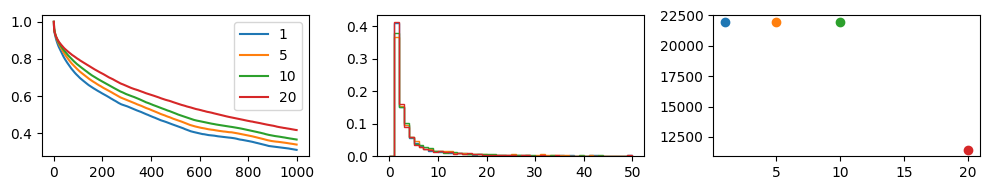

In [114]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2))
for i in [1, 5, 10,20]:
    dimer = ca_distances.contacts(1).sum(1) > i
    axes[0].plot(acf(dimer)[:1000], label=i)
    dimer_events = contiguous_bool(bools=dimer)
    dimer_lengths = np.fromiter(map(len, dimer_events), float) # scale by physical time
    axes[1].hist(dimer_lengths, range=(0,50), label=i, histtype='step', density=True, bins=50)
    axes[2].scatter(i, dimer_lengths.max())
axes[0].legend()
fig.tight_layout()

44

<Axes: >

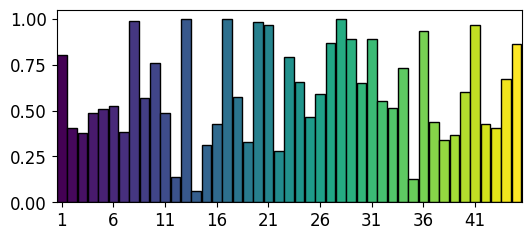

In [95]:
box_plot(group_by(microstates, dimer, np.mean), figsize=(6, 2.5), font_scale=2, label_stride=5)

<Axes: >

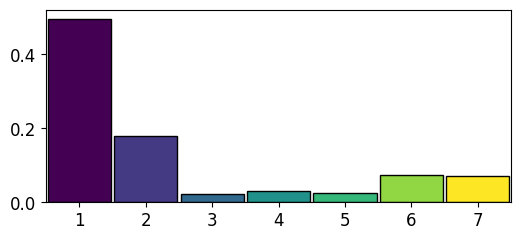

In [85]:
box_plot(group_by(macrostates, dimer, np.mean), figsize=(6, 2.5), font_scale=2)

['CA_' 'CB_' 'C_' 'HA_' 'H_' 'N_']
0.6620462586420391


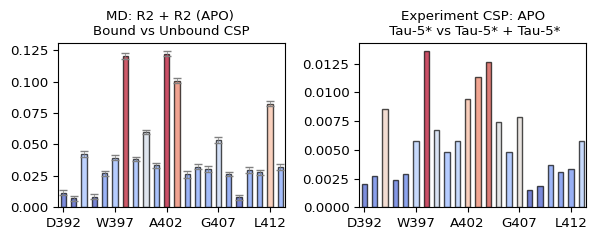

In [70]:
keys, values = load_dict('apo_cs.pkl')[::-1]
hn_comp_mu = np.stack(get_shifts('apo_cs.pkl')[-2:])[:, :-1].reshape(2, 2, 22, -1).mean(1) 
#hn_comp_mu_sep = .5 * (np.stack(get_shifts('apo_cs0.pkl')[-2:])[:, :-1] + np.stack(get_shifts('apo_cs1.pkl')[-2:])[:, :-1])

protein_csp_comp = np.linalg.norm((hn_comp_mu[..., dimer].mean(-1) - 
                   hn_comp_mu[..., ~dimer].mean(-1)) * np.array([1, 0.2]).reshape(2, 1), axis=0)

# disgusting code to propogate error through the CSP function

# hn_comp_mu_err_dimer = [monomer_aggr_stats(i, lower_upper=False) for i in 
#     np.stack(get_shifts('apo_cs.pkl')[-2:])[:, :-1].reshape(2, 44, -1).transpose(0, 2, 1)[:, dimer]]
# hn_comp_mu_err_not_dimer = [monomer_aggr_stats(i, lower_upper=False) for i in 
#     np.stack(get_shifts('apo_cs.pkl')[-2:])[:, :-1].reshape(2, 44, -1).transpose(0, 2, 1)[:, ~dimer]]

err = propagated_error(*np.concatenate([hn_comp_mu[...,dimer].mean(-1),
                                        hn_comp_mu[...,~dimer].mean(-1),
                                        hn_comp_mu[...,dimer].std(-1) / np.sum(dimer) ** .5,
                                        hn_comp_mu[...,~dimer].std(-1) / np.sum(~dimer) ** .5,
                                       ], 0)) * 1.92

where =  exp['monomer_protein']['CSP'].to_numpy()[1:-1] != 0.0

fig, axes = plt.subplots(1, 2, figsize=(6, 2.5))
scale = 1.6
box_plot(protein_csp_comp[where],
         ax=axes[0],
         errors=err[where],
         font_scale=scale,
         error_capsize=3,
         width=.5,
         labels=xticks[1:-1],
         #color_list='indianred',
         alpha=.7, 
         color_height=True,
         cmap='coolwarm', 
         title='MD: R2 + R2 (APO) \nBound vs Unbound CSP',
         label_stride=5)

# box_plot(exp['protein']['diff']['CSP'].to_numpy()[1:-1][where], ax=axes[1],
#          font_scale=scale, width=.5, color_height=True, cmap='coolwarm',
#          alpha=.7, title='Experimental R2 Protein CSP', label_stride=3,
#         )

box_plot(exp['monomer_protein']['CSP'].to_numpy()[1:-1][where],
         ax=axes[1],
         labels=xticks[1:-1],
         font_scale=scale, 
         width=.5, 
         color_height=True,
         cmap='coolwarm',
         alpha=.7,
         title = 'Experiment CSP: APO\n Tau-5* vs Tau-5* + Tau-5*', 
         label_stride=5,)


fig.tight_layout()
print(corr(exp['monomer_protein']['CSP'].to_numpy()[1:-1][where],
           protein_csp_comp[where] 
          )
     )
fig.savefig('apo_csp_comparison.png', dpi=1000, bbox_inches='tight')


In [36]:
apo_csp = np.copy(protein_csp_comp)

<Axes: title={'center': 'MD: R2 + R2 + EPI \nBound vs Unbound CSP'}>

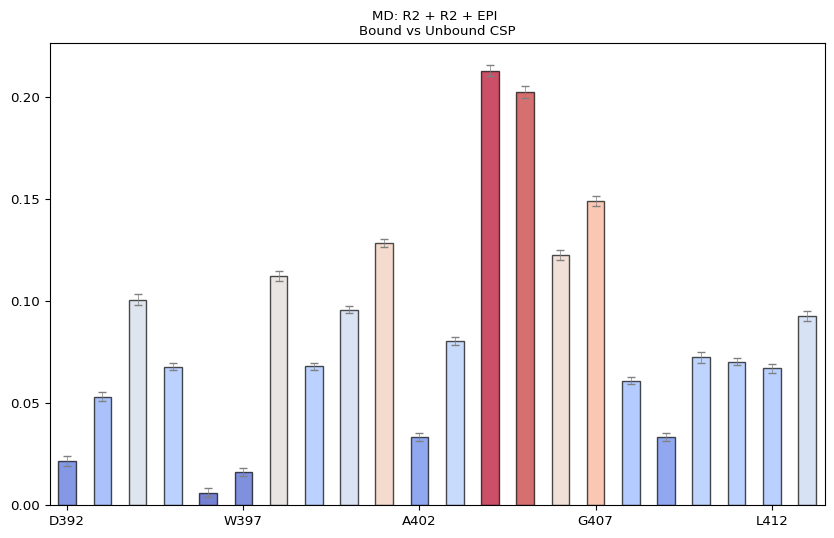

In [39]:
box_plot(protein_csp_comp - apo_csp,
         errors=err[where],
         labels=xticks[1:-1],
         font_scale=scale, 
         width=.5,
         error_capsize=3,
         #color_list='indianred',
         alpha=.7, 
         color_height=True,
         cmap='coolwarm', 
         title='MD: R2 + R2 + EPI \nBound vs Unbound CSP',
         label_stride=5)

In [38]:
protein_csp_comp - apo_csp

array([0.02183893, 0.05327049, 0.10069055, 0.06797742, 0.00616494,
       0.01636546, 0.11227534, 0.06813178, 0.09582825, 0.12851141,
       0.03355091, 0.0803271 , 0.2128893 , 0.20263403, 0.12238713,
       0.14894737, 0.06112434, 0.0334095 , 0.07249957, 0.07029015,
       0.06704084, 0.092963  ])

In [96]:
hn_comp = np.stack(get_shifts('epi_cs.pkl')[-2:])[:, :-1]
mu, err = block_error(hn_comp.transpose(2, 0, 1).reshape(-1, 88))
mu, err = mu.T.reshape(2, 2, 22,).mean(1), np.linalg.norm(err.reshape(2, 2, 22,), axis=1)

protein_csp_comp = np.linalg.norm((hn_comp_mu[..., epi_dimer].mean(-1) - 
                   hn_comp_mu[..., ~epi_dimer].mean(-1)) * np.array([1, 0.2]).reshape(2, 1), axis=0)

err = propagated_error(*np.concatenate([hn_comp_mu[...,epi_dimer].mean(-1),
                                        hn_comp_mu[...,~epi_dimer].mean(-1),
                                        err,
                                        err
                                       ], 0))

['CA_' 'CB_' 'C_' 'HA_' 'H_' 'N_']


['CA_' 'CB_' 'C_' 'HA_' 'H_' 'N_']
0.6640569821099382


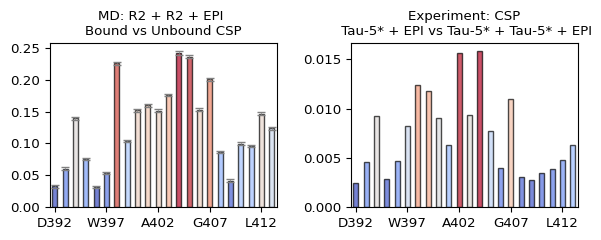

In [37]:
epi_dimer = np.load('./events/epi_dimer.npy')
keys, values = load_dict('epi_cs.pkl')[::-1]
hn_comp_mu = np.stack(get_shifts('epi_cs.pkl')[-2:])[:, :-1].reshape(2, 2, 22, -1).mean(1) 
#hn_comp_mu_sep = .5 * (np.stack(get_shifts('epi_cs0.pkl')[-2:])[:, :-1] + np.stack(get_shifts('epi_cs1.pkl')[-2:])[:, :-1])

protein_csp_comp = np.linalg.norm((hn_comp_mu[..., epi_dimer].mean(-1) - 
                   hn_comp_mu[..., ~epi_dimer].mean(-1)) * np.array([1, 0.2]).reshape(2, 1), axis=0)

err = propagated_error(*np.concatenate([hn_comp_mu[...,epi_dimer].mean(-1),
                                        hn_comp_mu[...,~epi_dimer].mean(-1),
                                        hn_comp_mu[...,epi_dimer].std(-1) / np.sum(dimer) ** .5,
                                        hn_comp_mu[...,~epi_dimer].std(-1) / np.sum(~dimer) ** .5,
                                       ], 0)) * 1.96

where =  exp['monomer_ligand']['CSP'].to_numpy()[1:-1] != 0.0



fig, axes = plt.subplots(1, 2, figsize=(6, 2.5))
scale = 1.6
box_plot(protein_csp_comp[where],
         ax=axes[0],
         errors=err[where],
         labels=xticks[1:-1],
         font_scale=scale, 
         width=.5,
         error_capsize=3,
         #color_list='indianred',
         alpha=.7, 
         color_height=True,
         cmap='coolwarm', 
         title='MD: R2 + R2 + EPI \nBound vs Unbound CSP',
         label_stride=5)

# box_plot(exp['protein']['diff']['CSP'].to_numpy()[1:-1][where], ax=axes[1],
#          font_scale=scale, width=.5, color_height=True, cmap='coolwarm',
#          alpha=.7, title='Experimental R2 Protein CSP', label_stride=3,
#         )

box_plot(exp['monomer_ligand']['CSP'].to_numpy()[1:-1][where],
         ax=axes[1],
         font_scale=scale,
         width=.5, 
         color_height=True, 
         cmap='coolwarm',
         alpha=.7, 
         labels=xticks[1:-1],
         title='Experiment: CSP\n Tau-5* + EPI vs Tau-5* + Tau-5* + EPI',
         label_stride=5,)


fig.tight_layout()
print(corr(exp['monomer_ligand']['CSP'].to_numpy()[1:-1][where],
           protein_csp_comp[where] 
          )
     )

fig.savefig('epi_csp_comparison.png', dpi=1000, bbox_inches='tight')


In [41]:
cut = 0.6
sequence, ca_index = get_residues(md.load(ligand_pdbs[0]))
ligand_name = 'EPI0'
ligand_index = isin_index(sequence, ligand_name)
ligand_distances = ResidueDistances(traj=md.load(ligand_files[0], top=ligand_pdbs[0]), index_0=ligand_index, index_1=ca_index)
#ternary = np.multiply.reduce([i.any(1) for i in split(ligand_distances.contacts(cut))])

In [137]:
# from the full set


apo_epi_csp = np.array([0.002460915,
                    0.000688052,
                    0.000751481,
                    0.00354993,
                    0.002241157,
                    0.002978969,
                    0.00193582,
                    0.006835494,
                    0.005190472,
                    0.002019038,
                    0.003502066,
                    0.003938139,
                    0.003188044,
                    0.003318241,
                    0.003605157,
                    0.002460915,
                    0.003428096,
                    0.00054831,
                    0.000430005,
                    0.003201402,
                    0.002735686,
                    0.001899483,
                    0.004012991,
                    0.001506254,])

In [53]:
ternary = np.multiply.reduce([i.any(1) for i in split(ligand_distances.contacts(.6))]).astype(bool)

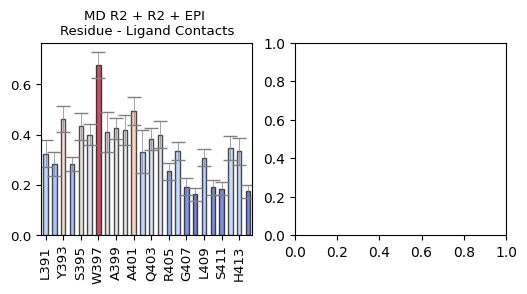

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(6, 2.5))

mu, err = monomer_aggr_stats(ligand_distances.contacts(0.6)[ternary])
box_plot(mu,
         ax=axes[0],
         labels=xticks,
         errors=err,
         font_scale=scale, 
         width=.5,
         #color_list='indianred',
         alpha=.7, 
         color_height=True,
         cmap='coolwarm', 
         title='MD R2 + R2 + EPI \nResidue - Ligand Contacts',
        label_stride=2, rotation=90)
fig.savefig('epi_contact_fractions.png', bbox_inches='tight', dpi=1000)

0.6147347114961805


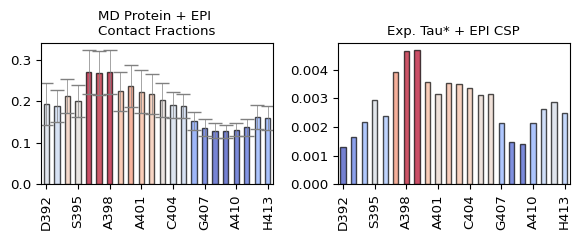

In [141]:
#index=0 # first ligand trajectory (1aa is second one, e.i (index = 1))
#, protein-ligand computations


# ca_distances = ca_distances = ResidueDistances(index_0=np.arange(24),
#                                 index_1=np.arange(24, 48),
#                                 traj=md.load(protein_files[1], top=protein_pdb, atom_indices=ca_selection)
#                                )
# dimer = ca_distances.contacts(1).any(1)
cut = .6
fig, axes = plt.subplots(1, 2, figsize=(6, 2.5))
scale = 1.6
window = 3
key = 'monomer_ligand' # not forcibly bound
where = apo_epi_csp != 0.0
mu, err = (i[where] for i in monomer_aggr_stats(ligand_distances.contacts(cut)))
box_plot(window_average(mu, window),
         ax=axes[0],
         labels=xticks[1:-1],
         errors=window_average(err, 3),
         font_scale=scale, 
         width=.5,
         #color_list='indianred',
         alpha=.7, 
         color_height=True,
         cmap='coolwarm', 
         title='MD Protein + EPI \nContact Fractions',
        label_stride=3, rotation=90)

box_plot(window_average(apo_epi_csp, window), ax=axes[1],
         font_scale=scale, width=.5, color_height=True, cmap='coolwarm',
         alpha=.7, title='Exp. Tau* + EPI CSP',
         label_stride=3,
         labels=xticks[1:-1], rotation=90
        )

print(corr(window_average(apo_epi_csp[where], window),
     window_average(mu, window))
     )
fig.tight_layout()

fig.savefig('epi_contact_fractions_vs_cs.png', dpi=1000, bbox_inches='tight')



# PRE

In [62]:
def compute_pre(traj,
                tag_idx,
                periodic: bool = True,
                #fill_zeros: bool = False,
                print_pairs: bool = False,
                ):

    """
    function to compute PREs for labeled residues (tag_idx), uses 0 indexing, fills zeros

    want output as tuple of (array(type_index), array(numerical results))
    """

    tag_idx = np.atleast_1d(tag_idx)

    sequence, residue_indices = get_residues(traj, slice_sequence=True)
    print(sequence, residue_indices)
    
    # remove proline
    bools = np.array([num_str(i, reverse=True) for i in sequence]) != 'PRO'
    residue_indices = residue_indices[bools]
    # get all the indices
    res_seq = np.array([traj.top.residue(i).resSeq for i in residue_indices])
    h_indices = np.array([traj.top.select(f'resid {i} and name H').item() for i in residue_indices])
    ca_indices = np.array([traj.top.select(f'resid {i} and name CA').item() for i in residue_indices])

    tag_idx = np.where(np.isin(residue_indices, tag_idx))[0]
    print(tag_idx)
    pairs = np.concatenate([product([ca_indices[i]], h_indices) for i in tag_idx])

    if print_pairs:
        print(np.array([(traj.top.atom(i), traj.top.atom(j)) for i, j in pairs]))

    d = md.compute_distances(traj.center_coordinates() if not periodic else traj,
                             pairs,
                             periodic=periodic).astype(np.float64)

    b=18.8; k=1.23e-32; tdelay=0.010; R2exp=4.0; tc=4.0e-9; wH=2.6752e8*b*2.0*np.pi


    b      = 18.79          # if you want to keep b
    k      = 1.23e-32       # leave as is
    tdelay = 0.001          # change this
    wH     = 2.6752e8 * b   # or 2*np.pi*800e6
    R2exp  = 4.0        # change this from a single constant
    tc     = 4.0e-9         # cannot be set from the paper
    # calculate PRE
    d = k*np.power(d,-6)*(4.0*tc+3.0*tc/(1.0+(wH*tc)**2))*1.0e42
    # calculate Iratios

    
    d = (R2exp*np.exp(-tdelay * d) / (d + R2exp)).reshape(traj.n_frames,
                                                          len(tag_idx),
                                                          len(residue_indices))#.transpose(1, 2, 0)

    d[:, np.arange(len(tag_idx)), tag_idx] = 0
    ids = np.array(list(chain(*[[f'PRE{res_seq[i]}_{j}' for j in res_seq] for i in tag_idx])))

    return [d.reshape(-1, d.shape[1] * d.shape[2]), ids]

In [63]:
selections = ['residue 1 to 24', 'residue 27 to 50']
pre_selections = ['residue 14 or ' +selections[1], 'residue 40 or ' + selections[0]]
pre_indices = [0, 24]
pre_inter = []
for i in range(2):
    pres = []
    for selection, index in zip(pre_selections, pre_indices):
        traj = md.load(protein_files[i], top=protein_pdb, atom_indices = md.load(protein_pdb).top.select(selection))
        pres.append(np.delete(compute_pre(traj, index)[0], index, axis=1))
        
    pre_inter.append(np.add.reduce(pres) / 2)

    

['CYS14' 'LEU27' 'ASP28' 'TYR29' 'GLY30' 'SER31' 'ALA32' 'TRP33' 'ALA34'
 'ALA35' 'ALA36' 'ALA37' 'ALA38' 'GLN39' 'CYS40' 'ARG41' 'TYR42' 'GLY43'
 'ASP44' 'LEU45' 'ALA46' 'SER47' 'LEU48' 'HIS49' 'GLY50'] [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24]
[0]
['LEU1' 'ASP2' 'TYR3' 'GLY4' 'SER5' 'ALA6' 'TRP7' 'ALA8' 'ALA9' 'ALA10'
 'ALA11' 'ALA12' 'GLN13' 'CYS14' 'ARG15' 'TYR16' 'GLY17' 'ASP18' 'LEU19'
 'ALA20' 'SER21' 'LEU22' 'HIS23' 'GLY24' 'CYS40'] [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24]
[24]
['CYS14' 'LEU27' 'ASP28' 'TYR29' 'GLY30' 'SER31' 'ALA32' 'TRP33' 'ALA34'
 'ALA35' 'ALA36' 'ALA37' 'ALA38' 'GLN39' 'CYS40' 'ARG41' 'TYR42' 'GLY43'
 'ASP44' 'LEU45' 'ALA46' 'SER47' 'LEU48' 'HIS49' 'GLY50'] [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24]
[0]
['LEU1' 'ASP2' 'TYR3' 'GLY4' 'SER5' 'ALA6' 'TRP7' 'ALA8' 'ALA9' 'ALA10'
 'ALA11' 'ALA12' 'GLN13' 'CYS14' 'ARG15' 'TYR16' 'GLY17' 'ASP18' 'LEU19'
 'ALA

In [64]:
pre_apo = np.array([0.467090038,
0.497776036,
0.434082566,
0.313703607,
0.107844251,
0.55053555,
0.223225818,
0.458279628,
0.376079258,
0.258323925,
0.626027833,
0.415897366,
0.40647308,
0.490905635,
0.378071239,
0.646480947,
0.478596642,
0.567612596,
0.497430783,
0.594060863,
0.629796778,
0.602669635,
0.687790511,
0.619549653,])

pre_epi = np.array([0.309529437,
0.35602248,
0.294830971,
0.0,
0.019504151,
0.390488005,
0.07529154,
0.372141133,
0.274601553,
0.324455918,
0.682610913,
0.220899945,
0.53245747,
0.369589434,
0.441344294,
0.724095674,
0.342271083,
0.493510566,
0.411766532,
0.487627224,
0.565100398,
0.499586659,
0.56011586,
0.573349045])

pre_apo_smooth = np.array([0.398477349,
0.38381071,
0.369281493,
0.353154797,
0.343407507,
0.345403755,
0.356554156,
0.371967769,
0.389799939,
0.409450183,
0.428181992,
0.442981891,
0.45499914,
0.468834966,
0.486963036,
0.507080452,
0.525645046,
0.542432621,
0.560168885,
0.580558702,
0.602222532,
0.622465658,
0.640169407,
0.656118126])
                    
                    

pre_epi_smooth = np.array([0.30144394,
                            0.276953961,
                            0.258090907,
                            0.240982633,
                            0.231075699,
                            0.235344696,
                            0.255876007,
                            0.289860581,
                            0.331208077,
                            0.371393896,
                            0.40273512,
                            0.423745192,
                            0.439789156,
                            0.456193133,
                            0.471605834,
                            0.480271482,
                            0.480494506,
                            0.478389295,
                            0.482177186,
                            0.49490278,
                            0.513964485,
                            0.535893531,
                            0.559822557,
                            0.586349139,])

In [194]:
from scipy.signal import savgol_filter
from scipy.ndimage import gaussian_filter1d

#y_smooth = savgol_filter(y, window_length=11, polyorder=3)

In [329]:
d = 0.5 * (np.power(ca_distances.matrix(contacts=False,cut_off=1)[:, 13, :], -6).mean(0) + 
          np.power(ca_distances.matrix(contacts=False,cut_off=1)[:, :, 13], -6).mean(0))
d = ca_distances.matrix(contacts=False,cut_off=1)[:, 13, :].astype(np.float64)

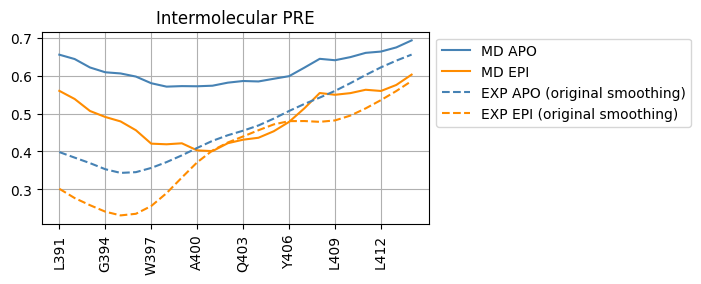

In [65]:
colors_exp = ["lightsteelblue", "orange"]
colors_sim = ["steelblue", "darkorange"]
plt.figure(figsize=(5, 2.5))
plt.plot(pre_inter[0].mean(0),
         label='MD APO',
         color = colors_sim[0])
plt.plot(pre_inter[1].mean(0),
         label='MD EPI',
         color = colors_sim[1])
#plt.plot(d.mean(0)*.6)
# plt.plot(gaussian_filter1d(pre_epi, 2.1, order=0))
# plt.plot(savgol_filter(pre_epi, window_length=16, polyorder=3, deriv=0))
plt.plot(pre_apo_smooth,
         label='EXP APO (original smoothing)',
         color = colors_sim[0], ls='--')

plt.plot(pre_epi_smooth,
         label='EXP EPI (original smoothing)',
         color = colors_sim[1], ls='--')

plt.xticks(np.arange(24)[::3], xticks[::3], rotation=90)
plt.grid()

plt.legend(ncol=1, bbox_to_anchor=[1, 1])
plt.title('Intermolecular PRE')
plt.savefig('inter_pre.png', dpi=1000, bbox_inches='tight')

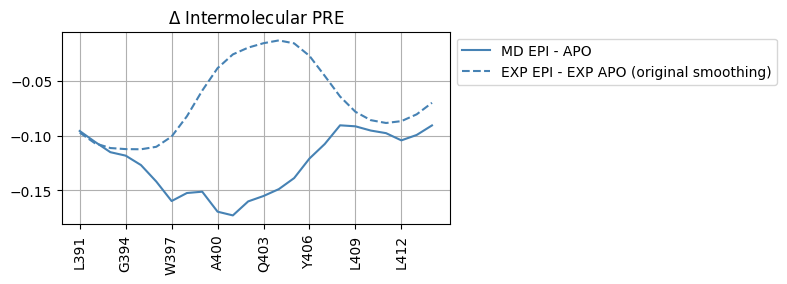

In [67]:
colors_exp = ["lightsteelblue", "orange"]
colors_sim = ["steelblue", "darkorange"]
plt.figure(figsize=(5, 2.5))
plt.plot(pre_inter[1].mean(0) - pre_inter[0].mean(0),
         label='MD EPI - APO',
         color = colors_sim[0])
#plt.plot(d.mean(0)*.6)
# plt.plot(gaussian_filter1d(pre_epi, 2.1, order=0))
# plt.plot(savgol_filter(pre_epi, window_length=16, polyorder=3, deriv=0))
plt.plot(pre_epi_smooth - pre_apo_smooth,
         label='EXP EPI - EXP APO (original smoothing)',
         color = colors_sim[0], ls='--')

plt.xticks(np.arange(24)[::3], xticks[::3], rotation=90)
plt.grid()

plt.legend(ncol=1, bbox_to_anchor=[1, 1])
plt.title(r'$\Delta$ Intermolecular PRE')
plt.savefig('inter_pre_delta.png', dpi=1000, bbox_inches='tight')

In [ ]:
selections = ['residue 1 to 24', 'residue 27 to 50']
#pre_selections = ['residue 14 or ' +selections[1], 'residue 40 or ' + selections[0]]
pre_indices = [13, 13]
pre_intra = []
for i in range(2):
    pres = []
    for selection, index in zip(selections, pre_indices):
        traj = md.load(protein_files[i], top=protein_pdb, atom_indices = md.load(protein_pdb).top.select(selection))
        pres.append(compute_pre(traj, index)[0])
        
    pre_intra.append(np.add.reduce(pres) / 2)

# comparing the gamma values form the main text - need to get the scaling right

0.6448329063427406

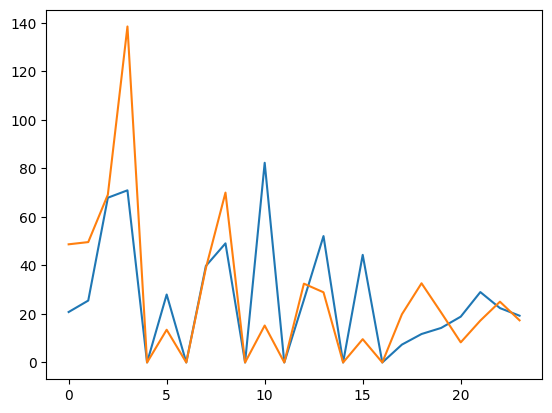

In [153]:
#plt.plot(np.power(ca_distances.matrix(contacts=False,cut_off=1)[:, 13, :], -6).mean(0) * 5e1)

gc = (1*np.power(ca_distances.matrix(contacts=False,cut_off=1)[:, :, 13], -6).mean(0) + 
      1*np.power(ca_distances.matrix(contacts=False,cut_off=1)[:, 13, :], -6).mean(0))*15
gc[where]=0
plt.plot(gc)
plt.plot(gamma_404)
corr(gamma_404, gc)

In [152]:
gamma_404_apo = np.array([48.72003148,
49.63511036,
69.18831913,
138.5317769,
0.0,
13.49040378,
0.0,
38.90640135,
70.03998836,
0.0,
15.2400812,
0.0,
32.49552476,
28.93963762,
0.0,
9.606575357,
0.0,
19.87258009,
32.64967819,
20.60424576,
8.294918065,
17.26913039,
25.06019961,
17.37853813])

gamma_404_epi = np.array([62.14071845,
36.25086007,
65.41415816,
0.0,
0.0,
0.0,
0.0,
64.09694727,
181.1015002,
0.0,
13.26561631,
0.0,
105.8099895,
93.32662643,
69.88777851,
17.10298122,
0.0,
34.04205152,
40.10231963,
26.3538417,
24.76910423,
44.98438937,
9.249910543,
45.44069282])

In [42]:
def csp(x, y, ):
    return np.linalg.norm((x - y) * np.array([1, 0.2]).reshape(2, 1), axis=0)

In [46]:
# taken from Fig_2I_1Tau5*_2Tau5*_CSPs_EPI001_1H_NMR

In [26]:
helix_monomer_dimer = np.array([
    [0.016, 0.02, 0.019, 0.02], # tau*, err, 2tau*, err
    [0.033, 0.02, 0.04, 0.02],
    [0.053, 0.02, 0.067, 0.02],
    [0.079, 0.02, 0.115, 0.02],
    [0.15,  0.02, 0.219, 0.02],
    [0.272, 0.02, 0.379, 0.02],
    [0.337, 0.02, 0.447, 0.02],
    [0.34,  0.02, 0.461, 0.02],
    [0.304, 0.02, 0.437, 0.02],
    [0.251, 0.02, 0.388, 0.02],
    [0.181, 0.02, 0.294, 0.02],
    [0.108, 0.02, 0.179, 0.02],
    [0.045, 0.02, 0.076, 0.02],
    [0.019, 0.02, 0.029, 0.02],
    [0.019, 0.02, 0.025, 0.02],
    [0.027, 0.02, 0.033, 0.02],
    [0.033, 0.02, 0.042, 0.02],
    [0.046, 0.02, 0.06,  0.02],
    [0.064, 0.02, 0.086, 0.02],
    [0.055, 0.02, 0.076, 0.02],
    [0.04,  0.02, 0.051, 0.02],
    [0.041, 0.02, 0.044, 0.02],
    [0.047, 0.02, 0.047, 0.02],
    [0.045, 0.02, 0.045, 0.02],
])


In [180]:

dssp_apo = np.where(md.compute_dssp(traj=md.load(protein_files[0], top=protein_pdb)) == 'H', 1, 0)[:, ca_index].reshape(-1, 2, 24
                                                                                                                   ).transpose(1, 0, 2)
dssp_epi = np.where(md.compute_dssp(traj=md.load(protein_files[1], top=protein_pdb)) == 'H', 1, 0)[:, ca_index].reshape(-1, 2, 24
                                                                                                                   ).transpose(1, 0, 2)

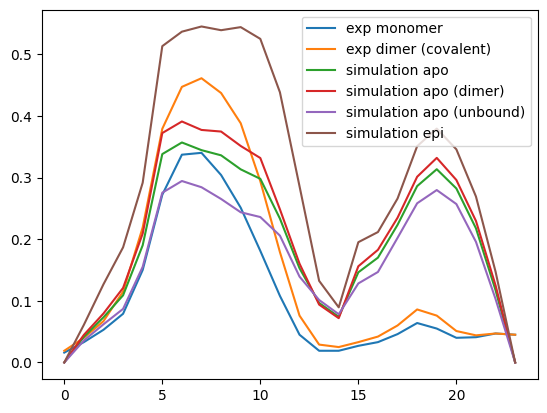

In [184]:
plt.plot(helix_monomer_dimer.T[0], label='exp monomer')
plt.plot(helix_monomer_dimer.T[2], label='exp dimer (covalent)')
plt.plot(dssp_apo.mean((0, 1)),label='simulation apo')
plt.plot(dssp_apo[:, dimer].mean((0, 1)),label='simulation apo (dimer)')
plt.plot(dssp_apo[:, ~dimer].mean((0, 1)),label='simulation apo (unbound)')
plt.plot(dssp_epi.mean((0, 1)), label='simulation epi')
plt.legend()

In [28]:
exp_helix_err = np.linalg.norm(helix_monomer_dimer[:, [1, 3]], axis=1)

In [24]:
mu, err = monomer_aggr_stats(dssp.transpose(1, 0,2).reshape(-1, 48), lower_upper=False, )

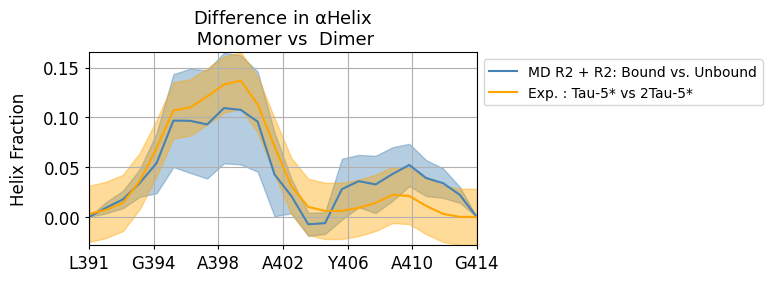

In [29]:
fig, ax = plt.subplots(1, 1,figsize=(5, 2.5))
md_diff = dssp[:, dimer].mean((0, 1)) - dssp[:, ~dimer].mean((0, 1))
lineplot1D(dssp[:, dimer].mean((0, 1)) - dssp[:, ~dimer].mean((0, 1)),
           y1=md_diff - err , y2=md_diff + err,
           label='MD R2 + R2: Bound vs. Unbound',
           color='steelblue', fill_color='steelblue',
           fill_alpha=.4,
           ax=ax)
exp_diff = helix_monomer_dimer.T[2] - helix_monomer_dimer.T[0]
lineplot1D(helix_monomer_dimer.T[2] - helix_monomer_dimer.T[0], 
           y1=exp_diff - exp_helix_err, y2=exp_diff + exp_helix_err ,
           label='Exp. : Tau-5* vs 2Tau-5*',
           color='orange', fill_color='orange',
           fill_alpha=.4, title=r'Difference in $\alpha$Helix'+'\n Monomer vs  Dimer',
           ax=ax, xticks=xticks, label_stride=3, ylabel='Helix Fraction', ylabel_rotation=90)
ax.grid()

ax.legend(bbox_to_anchor=[1,1])

fig.savefig('delta_helix.png', dpi=1000, bbox_inches='tight')

In [16]:


csp_matrix_apo = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.032113485743035144, 0.10175878807590559, 0.028209276328557922, 0.034930607, 0.068700958, 0.16209937258939805, 0.080045639, 0.057767598, 0.068495171, 0.1125143958402493, 0.13503158907227994, 0.1512043447630363, 0.088991276, 0.057445979, 0.09327166, 0.0, 0.0, 0.044035896, 0.037056873999109036, 0.040079437, 0.068650715, 0.053502644],
    [0.0, 0.0, 0.10175878807590559, 0.32244556176598965, 0.089387424, 0.11068546985024835, 0.2176944056502887, 0.5136482484197252, 0.25364257594109063, 0.18304960202943432, 0.21704232320702424, 0.3565271192735483, 0.42787790045305224, 0.4791249071501064, 0.28198883438919575, 0.18203047880700257, 0.2955521921154751, 0.0, 0.0, 0.13953762132218897, 0.11742302340532147, 0.12700069138664757, 0.2175352001718991, 0.1695351371151123],
    [0.0, 0.0, 0.028209276328557922, 0.089387424, 0.024779723, 0.030683905180089628, 0.060348612245552456, 0.14239207884967572, 0.07031406, 0.05074448, 0.060167844, 0.098835415, 0.1186150715529336, 0.13282161823320954, 0.078172127, 0.050461962, 0.081932122, 0.0, 0.0, 0.038682214996223305, 0.032551670250873896, 0.035206764, 0.060304477764218406, 0.046998039],
    [0.0, 0.0, 0.034930607, 0.11068546985024835, 0.030683905180089628, 0.037994858, 0.074727676, 0.17631936815230512, 0.087067558, 0.0628352, 0.074503837, 0.12238460189998673, 0.14687709203004826, 0.16446858556345548, 0.096797942, 0.062485366, 0.10145381772478379, 0.0, 0.0, 0.047898898, 0.040307649, 0.043595363, 0.074673026, 0.058196107],
    [0.0, 0.0, 0.068700958, 0.2176944056502887, 0.060348612245552456, 0.074727676, 0.14697319445762969, 0.34678210343671745, 0.17124307593098947, 0.12358326193132514, 0.14653295053197607, 0.24070407079999417, 0.28887550729453193, 0.3234741744406098, 0.1903806377925111, 0.12289521579114379, 0.19953774041372038, 0.0, 0.0, 0.094206784, 0.079276437, 0.08574266, 0.14686570920708233, 0.11445916857711069],
    [0.0, 0.0, 0.16209937258939805, 0.5136482484197252, 0.14239207884967572, 0.17631936815230512, 0.34678210343671745, 0.8182296622712577, 0.40404669905600815, 0.2915937404794632, 0.34574335133551437, 0.5679393734744353, 0.6815995013282928, 0.7632347860024832, 0.44920162667039026, 0.28997030099014603, 0.4708077387242743, 0.0, 0.0, 0.22228017153733726, 0.18705213359414727, 0.20230913497946681, 0.34652849282826076, 0.2700655135330208],
    [0.0, 0.0, 0.080045639, 0.25364257594109063, 0.07031406, 0.087067558, 0.17124307593098947, 0.40404669905600815, 0.1995206756070093, 0.14399073235634277, 0.17073013393318465, 0.28045185807527995, 0.3365779087322046, 0.37688990036490244, 0.22181844882395685, 0.14318906823070476, 0.23248767612937318, 0.0, 0.0, 0.10976327761812459, 0.092367462, 0.09990146, 0.171117841, 0.1333599651826211],
    [0.0, 0.0, 0.057767598, 0.18304960202943432, 0.05074448, 0.0628352, 0.12358326193132514, 0.2915937404794632, 0.14399073235634277, 0.10391570167571926, 0.12321308027623833, 0.20239741225865213, 0.24290264367776557, 0.2719951333672452, 0.1600826621057583, 0.10333715409310289, 0.16778246488915072, 0.0, 0.0, 0.07921432, 0.066660051, 0.072097212, 0.12349288233577262, 0.096243655],
    [0.0, 0.0, 0.068495171, 0.21704232320702424, 0.060167844, 0.074503837, 0.14653295053197607, 0.34574335133551437, 0.17073013393318465, 0.12321308027623833, 0.14609402531423238, 0.23998306514014686, 0.288010209, 0.32250523897636535, 0.189810371, 0.12252709511142668, 0.1989400444972646, 0.0, 0.0, 0.093924597, 0.079038972, 0.085485826, 0.14642578724305463, 0.11411631725726705],
    [0.0, 0.0, 0.1125143958402493, 0.3565271192735483, 0.098835415, 0.12238460189998673, 0.24070407079999417, 0.5679393734744353, 0.28045185807527995, 0.20239741225865213, 0.23998306514014686, 0.3942109982265607, 0.4731033493339004, 0.5297670155013784, 0.31179423354894464, 0.20127057067743018, 0.3267911987152274, 0.0, 0.0, 0.15428634181787215, 0.129834295, 0.14042429487272995, 0.24052803776585369, 0.1874545077322643],
    [0.0, 0.0, 0.13503158907227994, 0.42787790045305224, 0.1186150715529336, 0.14687709203004826, 0.28887550729453193, 0.6815995013282928, 0.3365779087322046, 0.24290264367776557, 0.288010209, 0.4731033493339004, 0.5677842073353748, 0.6357878154791662, 0.3741927466727469, 0.2415502904236881, 0.39219101278386764, 0.0, 0.0, 0.18516323846591315, 0.15581767180899053, 0.16852701860428107, 0.288664245, 0.22496925721210492],
    [0.0, 0.0, 0.1512043447630363, 0.4791249071501064, 0.13282161823320954, 0.16446858556345548, 0.3234741744406098, 0.7632347860024832, 0.37688990036490244, 0.2719951333672452, 0.32250523897636535, 0.5297670155013784, 0.6357878154791662, 0.7119362269845676, 0.4190098736485099, 0.2704808085409152, 0.43916379505978836, 0.0, 0.0, 0.2073402700715734, 0.17447998005688023, 0.18871152741369498, 0.32323761, 0.25191386224726264],
    [0.0, 0.0, 0.088991276, 0.28198883438919575, 0.078172127, 0.096797942, 0.1903806377925111, 0.44920162667039026, 0.22181844882395685, 0.1600826621057583, 0.189810371, 0.31179423354894464, 0.3741927466727469, 0.4190098736485099, 0.24660814769683856, 0.15919140663919662, 0.2584697326871538, 0.0, 0.0, 0.12203005981717108, 0.10269014502532493, 0.1110661183692562, 0.19024140757010216, 0.14826383542471663],
    [0.0, 0.0, 0.057445979, 0.18203047880700257, 0.050461962, 0.062485366, 0.12289521579114379, 0.28997030099014603, 0.14318906823070476, 0.10333715409310289, 0.12252709511142668, 0.20127057067743018, 0.2415502904236881, 0.2704808085409152, 0.15919140663919662, 0.10276182755696892, 0.16684834099928897, 0.0, 0.0, 0.078773297, 0.066288923, 0.071695813, 0.12280533938130508, 0.095707821],
    [0.0, 0.0, 0.09327166, 0.2955521921154751, 0.081932122, 0.10145381772478379, 0.19953774041372038, 0.4708077387242743, 0.23248767612937318, 0.16778246488915072, 0.1989400444972646, 0.3267911987152274, 0.39219101278386764, 0.43916379505978836, 0.2584697326871538, 0.16684834099928897, 0.2709018470772333, 0.0, 0.0, 0.1278995736163422, 0.10762942985537478, 0.11640827845149679, 0.19939181336830805, 0.15539516543674173],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.044035896, 0.13953762132218897, 0.038682214996223305, 0.047898898, 0.094206784, 0.22228017153733726, 0.10976327761812459, 0.07921432, 0.093924597, 0.15428634181787215, 0.18516323846591315, 0.2073402700715734, 0.12203005981717108, 0.078773297, 0.1278995736163422, 0.0, 0.0, 0.060384604637185944, 0.05081456, 0.054959275, 0.094137889, 0.073365965],
    [0.0, 0.0, 0.037056873999109036, 0.11742302340532147, 0.032551670250873896, 0.040307649, 0.079276437, 0.18705213359414727, 0.092367462, 0.066660051, 0.079038972, 0.129834295, 0.15581767180899053, 0.17447998005688023, 0.10269014502532493, 0.066288923, 0.10762942985537478, 0.0, 0.0, 0.05081456, 0.042761223, 0.046249063176776135, 0.07921846, 0.061738572],
    [0.0, 0.0, 0.040079437, 0.12700069138664757, 0.035206764, 0.043595363, 0.08574266, 0.20230913497946681, 0.09990146, 0.072097212, 0.085485826, 0.14042429487272995, 0.16852701860428107, 0.18871152741369498, 0.1110661183692562, 0.071695813, 0.11640827845149679, 0.0, 0.0, 0.054959275, 0.046249063176776135, 0.050021391, 0.085679954, 0.066774309],
    [0.0, 0.0, 0.068650715, 0.2175352001718991, 0.060304477764218406, 0.074673026, 0.14686570920708233, 0.34652849282826076, 0.171117841, 0.12349288233577262, 0.14642578724305463, 0.24052803776585369, 0.288664245, 0.32323761, 0.19024140757010216, 0.12280533938130508, 0.19939181336830805, 0.0, 0.0, 0.094137889, 0.07921846, 0.085679954, 0.1467583025632437, 0.11437546166404162],
    [0.0, 0.0, 0.053502644, 0.1695351371151123, 0.046998039, 0.058196107, 0.11445916857711069, 0.2700655135330208, 0.1333599651826211, 0.096243655, 0.11411631725726705, 0.1874545077322643, 0.22496925721210492, 0.25191386224726264, 0.14826383542471663, 0.095707821, 0.15539516543674173, 0.0, 0.0, 0.073365965, 0.061738572, 0.066774309, 0.11437546166404162, 0.089138032]
], dtype=float)
csp_matrix_apo = csp_matrix_apo



import numpy as np

csp_matrix_epi = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.054952978037945494, 0.077743675, 0.027767084229696093, 0.055251322, 0.088979337, 0.080422829, 0.14420450596131906, 0.11342541286487895, 0.053657209, 0.18424000863841342, 0.049564676, 0.15334146444147695, 0.0610765, 0.021024612942947093, 0.11594657934295088, 0.0, 0.0, 0.024079967591773485, 0.038477163, 0.05070916, 0.054183543256999325, 0.032272651633612676],
    [0.0, 0.0, 0.077743675, 0.051648675, 0.026872456573170805, 0.075428629, 0.10858240992211757, -0.005434228, 0.20838614824451354, 0.16928653247730233, 0.037445754, 0.2556289522079219, -0.039732808, 0.15314351778818536, 0.031204719422880722, -0.017027607, 0.13760767667025364, 0.0, 0.0, 0.00303295, 0.039343085447841264, 0.060920938, 0.038347838, 0.009777253],
    [0.0, 0.0, 0.027767084229696093, 0.026872456573170805, 0.011390224745814519, 0.027335551154307386, 0.041280001434369294, 0.015276319441026448, 0.073795658, 0.059188855, 0.018929531933475012, 0.092026118, 0.001674713, 0.063910501, 0.019117787503962466, 0.000673473, 0.052964777700350824, 0.0, 0.0, 0.005565349, 0.016231502878796215, 0.023321176, 0.01922898, 0.008674068],
    [0.0, 0.0, 0.055251322, 0.075428629, 0.027335551154307386, 0.055422863507296166, 0.088650749, 0.075266247, 0.1451926988930866, 0.1144550342173331, 0.052143807, 0.1850046795594918, 0.044679598, 0.1511808723315916, 0.058818086, 0.018944292, 0.11533621394971763, 0.0, 0.0, 0.022754642, 0.037977975114471964, 0.050476858, 0.052680386, 0.030764430464647115],
    [0.0, 0.0, 0.088979337, 0.10858240992211757, 0.041280001434369294, 0.088650749, 0.13894454313116922, 0.094869197, 0.23479208849943273, 0.18627284799524996, 0.075474939, 0.2968307161162544, 0.047678805, 0.22937180537878993, 0.082524911, 0.020173195692647194, 0.17990339267044891, 0.0, 0.0, 0.029787343, 0.057826563, 0.078899568, 0.076373868, 0.041615789],
    [0.0, 0.0, 0.080422829, -0.005434228, 0.015276319441026448, 0.075266247, 0.094869197, -0.125905381, 0.21998238923019825, 0.18401986823173078, -7.48e-05, 0.25937201049734926, -0.151944312, 0.094053478, -0.023418877, -0.064807162, 0.11568644808536255, 0.0, 0.0, -0.028175582, 0.02547132, 0.052104104, 0.001017267, -0.026088621],
    [0.0, 0.0, 0.14420450596131906, 0.20838614824451354, 0.073795658, 0.1451926988930866, 0.23479208849943273, 0.21998238923019825, 0.3780851446188521, 0.2969830260948883, 0.14368924650117385, 0.4838488432469511, 0.13830431805505755, 0.407174805, 0.1644139040128221, 0.058679691, 0.3062425046045161, 0.0, 0.0, 0.065516957, 0.10210154729437365, 0.13387958107390469, 0.14505861247928437, 0.087379219],
    [0.0, 0.0, 0.11342541286487895, 0.16928653247730233, 0.059188855, 0.1144550342173331, 0.18627284799524996, 0.18401986823173078, 0.2969830260948883, 0.23278162835215904, 0.11656638877218253, 0.38103878457795115, 0.11891250615117038, 0.326148611, 0.13441066184394626, 0.050467187178070125, 0.24331422894032997, 0.0, 0.0, 0.054394134, 0.081700317, 0.10630169214046892, 0.11762895917330547, 0.072036891],
    [0.0, 0.0, 0.053657209, 0.037445754, 0.018929531933475012, 0.052143807, 0.075474939, -7.48e-05, 0.14368924650117385, 0.11656638877218253, 0.027030392897091415, 0.17658507533362716, -0.024035545, 0.10766379194804526, 0.023239038, -0.010309944, 0.095789027, 0.0, 0.0, 0.003050196, 0.027619198559151736, 0.042380071146054396, 0.027648139048653625, 0.007854415],
    [0.0, 0.0, 0.18424000863841342, 0.2556289522079219, 0.092026118, 0.1850046795594918, 0.2968307161162544, 0.25937201049734926, 0.4838488432469511, 0.38103878457795115, 0.17658507533362716, 0.617266498, 0.15671973615247514, 0.5086149395265143, 0.20001905014945104, 0.066463291, 0.3864578998767741, 0.0, 0.0, 0.078061493, 0.127702861, 0.16908065378790735, 0.17836326050414927, 0.10511187622797899],
    [0.0, 0.0, 0.049564676, -0.039732808, 0.001674713, 0.044679598, 0.047678805, -0.151944312, 0.13830431805505755, 0.11891250615117038, -0.024035545, 0.15671973615247514, -0.162156168, 0.018179005066040976, -0.048861169, -0.069111048, 0.054816776258743705, 0.0, 0.0, -0.036719558, 0.006285678, 0.025364367, -0.023264307, -0.038455771],
    [0.0, 0.0, 0.15334146444147695, 0.15314351778818536, 0.063910501, 0.1511808723315916, 0.22937180537878993, 0.094053478, 0.407174805, 0.326148611, 0.10766379194804526, 0.5086149395265143, 0.018179005066040976, 0.35812662373458704, 0.11006407912587907, 0.007521512, 0.2946419400010871, 0.0, 0.0, 0.03325707, 0.090864038, 0.12966881614116563, 0.1093046701339696, 0.050818689999455297],
    [0.0, 0.0, 0.0610765, 0.031204719422880722, 0.019117787503962466, 0.058818086, 0.082524911, -0.023418877, 0.1644139040128221, 0.13441066184394626, 0.023239038, 0.20001905014945104, -0.048861169, 0.11006407912587907, 0.015647361577990626, -0.020890397, 0.10386156709405925, 0.0, 0.0, -0.002602435, 0.028484177261507093, 0.046122416, 0.023973022246447706, 0.001917513],
    [0.0, 0.0, 0.021024612942947093, -0.017027607, 0.000673473, 0.018944292, 0.020173195692647194, -0.064807162, 0.058679691, 0.050467187178070125, -0.010309944, 0.066463291, -0.069111048, 0.007521512, -0.020890397, -0.029455024, 0.023173872870309725, 0.0, 0.0, -0.015668213, 0.002621402, 0.010727013327764351, -0.009982327, -0.016419104],
    [0.0, 0.0, 0.11594657934295088, 0.13760767667025364, 0.052964777700350824, 0.11533621394971763, 0.17990339267044891, 0.11568644808536255, 0.3062425046045161, 0.24331422894032997, 0.095789027, 0.3864578998767741, 0.054816776258743705, 0.2946419400010871, 0.10386156709405925, 0.023173872870309725, 0.23266830397113664, 0.0, 0.0, 0.036749384, 0.074347684, 0.10209176627789036, 0.096970879, 0.051840139],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.024079967591773485, 0.00303295, 0.005565349, 0.022754642, 0.029787343, -0.028175582, 0.065516957, 0.054394134, 0.003050196, 0.078061493, -0.036719558, 0.03325707, -0.002602435, -0.015668213, 0.036749384, 0.0, 0.0, -0.005957258, 0.008832086, 0.016465076, 0.003364597, -0.004945273],
    [0.0, 0.0, 0.038477163, 0.039343085447841264, 0.016231502878796215, 0.037977975114471964, 0.057826563, 0.02547132, 0.10210154729437365, 0.081700317, 0.027619198559151736, 0.127702861, 0.006285678, 0.090864038, 0.028484177261507093, 0.002621402, 0.074347684, 0.0, 0.0, 0.008832086, 0.023036892756214754, 0.032706909, 0.028028464, 0.013314789],
    [0.0, 0.0, 0.05070916, 0.060920938, 0.023321176, 0.050476858, 0.078899568, 0.052104104, 0.13387958107390469, 0.10630169214046892, 0.042380071146054396, 0.16908065378790735, 0.025364367, 0.12966881614116563, 0.046122416, 0.010727013327764351, 0.10209176627789036, 0.0, 0.0, 0.016465076, 0.032706909, 0.044786688505175705, 0.04289496, 0.023126340031398927],
    [0.0, 0.0, 0.054183543256999325, 0.038347838, 0.01922898, 0.052680386, 0.076373868, 0.001017267, 0.14505861247928437, 0.11762895917330547, 0.027648139048653625, 0.17836326050414927, -0.023264307, 0.1093046701339696, 0.023973022246447706, -0.009982327, 0.096970879, 0.0, 0.0, 0.003364597, 0.028028464, 0.04289496, 0.028270501357287814, 0.008260365],
    [0.0, 0.0, 0.032272651633612676, 0.009777253, 0.008674068, 0.030764430464647115, 0.041615789, -0.026088621, 0.087379219, 0.072036891, 0.007854415, 0.10511187622797899, -0.038455771, 0.050818689999455297, 0.001917513, -0.016419104, 0.051840139, 0.0, 0.0, -0.004945273, 0.013314789, 0.023126340031398927, 0.008260365, -0.003114451],
])
csp_matrix_epi = csp_matrix_epi

In [58]:
for i in (csp_matrix_apo, csp_matrix_epi):
    print(i.shape)

(24, 24)
(24, 24)


In [104]:
contact_epi_mean = ca_distances = ResidueDistances(index_0=np.arange(24),
                                index_1=np.arange(24, 48),
                                traj=md.load(protein_files[1], top=protein_pdb, atom_indices=ca_selection)
                               ).matrix(contacts=True, cut_off=.8).mean(0)



KeyboardInterrupt: 

In [17]:
# throw away 1-off function to get past expensive nearest heavy calcuation for this system specifically
from writhe_tools.md_tools import to_distance_matrix, to_contacts, residue_distances
def inter_distances(traj_file, top_file=protein_pdb):
    top = md.load(protein_pdb)
    sequence, ca_index = get_residues(top)
    selection = 'or '.join([f'residue {i} '  for i in ca_index])
    traj=md.load(traj_file,
                 top=top_file,
                 atom_indices=top.top.select(selection)
                )
    
    pairs = product(np.arange(0, 24), np.arange(24, 48))
    
    distances = []
    for batch in np.array_split(pairs, 10, axis=0):
        distances.append(residue_distances(traj, indices=batch)[0])
    return np.concatenate(distances, axis=1)
    


In [37]:
#contact_mean = ca_distances.matrix(contacts=True, cut_off=.8).mean(0)
contact_mean_apo = to_contacts(apo_residue_distances, .6).mean(0).reshape(24, 24)

In [18]:
contact_mean_apo = to_contacts(inter_distances(protein_files[0]), .6).mean(0).reshape(24, 24)
contact_mean_epi = to_contacts(inter_distances(protein_files[1]), .6).mean(0).reshape(24, 24)

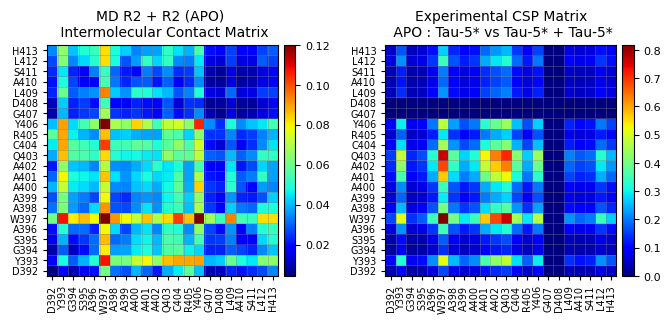

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))

plot_distance_matrix(csp_matrix_apo[2:, 2:],
                     xticks=xticks[1:-1], yticks=xticks[1:-1], xticks_rotation=90, grid=True, ax=axes[1],
                    title='Experimental CSP Matrix\n APO : Tau-5* vs Tau-5* + Tau-5*', label_stride=1, grid_linewidth=0.5,)

plot_distance_matrix(((contact_mean_apo.T + contact_mean_apo) / 2)[1:-1, 1:-1], 
                    xticks=xticks[1:-1], yticks=xticks[1:-1],
                     xticks_rotation=90,
                     grid=True, ax=axes[0], 
                    title='MD R2 + R2 (APO) \n Intermolecular Contact Matrix', 
                     label_stride=1,grid_linewidth=0.5,
                     vmax=.12
                 
                    )



#fig.suptitle('      APO', y=1)

fig.savefig('apo_csp_matrix.png', dpi=1000, bbox_inches='tight')

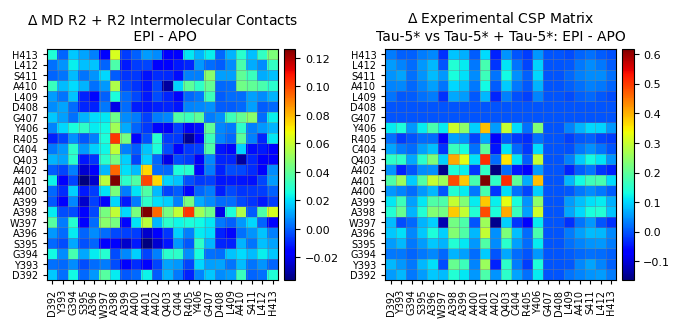

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
plot_distance_matrix(csp_matrix_epi[2:, 2:],
                     xticks=xticks[1:-1], 
                     yticks=xticks[1:-1],
                     xticks_rotation=90, grid=True,
                     ax=axes[1],
                    title=r'$\Delta$ Experimental CSP Matrix'+'\nTau-5* vs Tau-5* + Tau-5*: EPI - APO', label_stride=1,
                    grid_linewidth=0.5,)

plot_distance_matrix(((contact_mean_epi.T + contact_mean_epi) / 2 - (contact_mean_apo.T + contact_mean_apo) / 2)[:-2,:-2], 
                        xticks=xticks[1:-1], yticks=xticks[1:-1],
                     xticks_rotation=90,
                     grid=True, ax=axes[0], 
                    title=r'$\Delta$ MD R2 + R2 Intermolecular Contacts'+'\n EPI - APO', label_stride=1,
                    grid_linewidth=0.5,)

#fig.suptitle('      EPI - APO', y=1, )
fig.savefig('apo_epi_diff_csp_matrix.png', dpi=1000, bbox_inches='tight')

In [3]:
from writhe_tools.stats import DensityComparator, dKL, dJS

In [4]:

macrostates = load_dict('density_clusters.pkl')[0]
microstates = load_dict('msm_clusters.pkl')[0]

# msms = [MarkovModel(i).estimate_msm(lag, 10, reversible=False) for i, lag in zip(microstates, (150, 300, 150))]
# fig, axes = plt.subplots(1, 3, figsize=(16, 3), sharey=True)
# for model, ax, label in zip(msms, axes.flat, labels):
#     model.its('msm', ax=ax, n_its=5, cmap='coolwarm')

In [90]:
from deeptime.decomposition import TICA

In [91]:
proj = TICA(250).fit_transform(writhe_features)

In [129]:
dtraj = np.load('most_converged_apo_dtraj.npy')

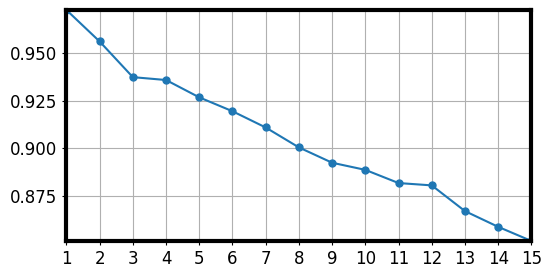

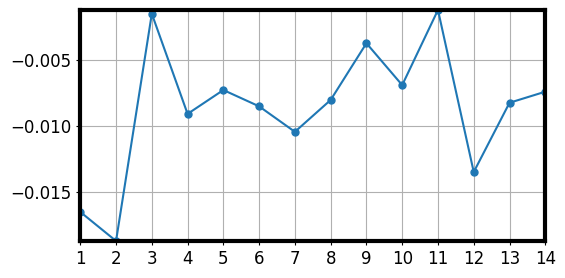

In [764]:
lineplot1D(tcca.svals[:15],
           xticks=np.arange(1, 16),
           grid=True,
           marker='.', 
           ms=10, 
           figsize=(6, 3),
           label_stride=1)
lineplot1D(np.diff(tcca.svals[:15]),
           xticks=np.arange(1, 15),
           grid=True,
           marker='.', 
           ms=10, 
           figsize=(6, 3),
           label_stride=1)

In [51]:
tcca = tCCA(writhe_features, lag=250, dim=50, epsilon=1e-6).fit()
proj = tcca.transform()

In [194]:
np.save('best_micro_dtraj_apo.npy', msm.dtraj)
dtraj = np.load('best_micro_dtraj_apo.npy')

In [172]:
dtraj = Kmeans(proj, 250, 5, max_iter=500)[0]

In [6]:
lag, steps = 50, 20
lags = np.arange(1, steps + 1) * lag
msm = MarkovModel(dtraj, 1).estimate_msm(lag, steps, reversible=False)
sets = group_by(*group_by(msm.dtraj, macrostates, mode, return_keys=True))

In [7]:
msm_rev =  MarkovModel(msm.dtraj).estimate_msm(lag, steps, reversible=True)

(1000, 50000)

findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXNonUnicode'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXNonUnicode'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXNonUnicode'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeOneSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeTwoSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeThreeSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeFourSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeFiveSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmsy10'] not

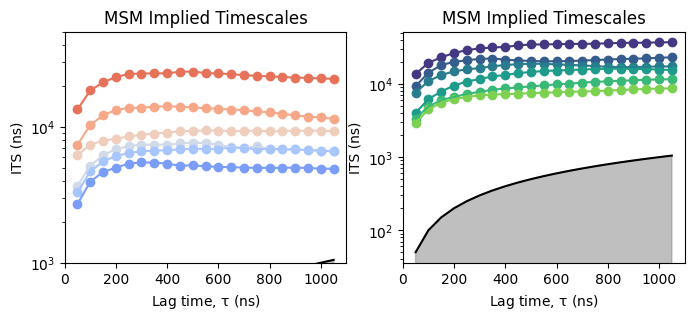

In [8]:
_,ax = plt.subplots(1, 2, figsize=(8, 3))
msm.its('msm', n_its=6, ax=ax[0], cmap='coolwarm_r')
msm_rev.its('msm', n_its=6, ax=ax[1])
ax[0].set_ylim(1000, 50000)

In [899]:
msm_index = -1

$$
p(x) \propto e^{-U(x)\beta}
$$

$$
\beta = \frac{1}{k_{b}T}
$$

$$
p(x) = \frac{e^{-U(x)\beta}}{\int{e^{-U(x)\beta}}dx} = \frac{e^{-U(x)\beta}}{Z}
$$

$$
-\log p(x) = U(x)\beta + \log Z
$$
Normalization just shifts the free energy by a constant
$$
-\log p(x) \propto U(x)\beta
$$

Therefore, we can estimate the free energy via a histogram to get a representation proportional to $p(x)$, with or without normalization and scaling by a constant, by taking a negative log of the histogram


<Axes: title={'center': 'MFPT Matrix : APO'}, xlabel='$State_{i}$', ylabel='$State_{j}$'>

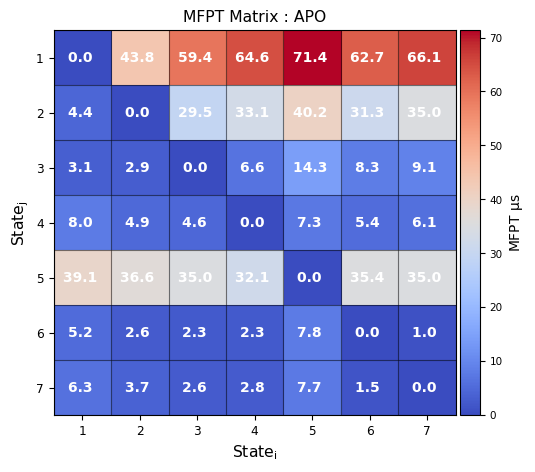

In [190]:

def mfpt_mat(tmat, states, dt=1, lag=1, mu=None):
    nstates = len(states)
    mfpt = np.zeros((nstates, nstates))
    for i, s0 in enumerate(states):
        for j, s1 in enumerate(states):
            mfpt[i, j] = deeptime.markov.tools.analysis.mfpt(tmat, s0, s1)
    return mfpt * dt * lag

mode =lambda x : np.bincount(x).argmax()
tmat = msm.msm['data']['tmats'][8]
sets = group_by(*group_by(msm.dtraj, macrostates, mode, return_keys=True))
annotated_matrix_plot(mfpt_mat(tmat, sets, lag=lags[8]) * 0.24e-3,
                      decimals=1,
                      cmap='coolwarm', 
                      title = f'MFPT Matrix : {label}',
                      font_scale=.25,
                      cbar_label=r'MFPT $\mu$s',
                      grid=True, grid_alpha=.3, 
                      figsize=(5.5,5)
                      )

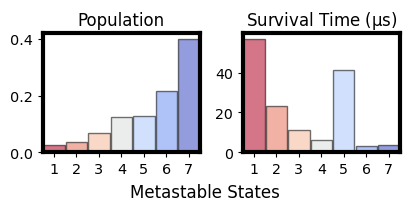

In [901]:
from itertools import chain

stationary_distribution = np.array([msm.msm['msms'][msm_index].stationary_distribution[i].sum() for i in sets])

survival_times = []
ids = set(range(7))
for i in range(7):
    survival_times.append(deeptime.markov.tools.analysis.mfpt(tmat, 
                                                              sets[i],
                                                              list(chain(*reindex_list(sets, list(ids - {i})))))
                         )
survival_times = np.array(survival_times)
fig, axes = plt.subplots(1, 2, figsize=(4.2, 2.3))
box_plot(stationary_distribution, cmap='coolwarm_r', alpha=.55, ax=axes[0], font_scale=1.73, title='Population')
axes[0].set_title('Population')

box_plot(survival_times * lags[msm_index] * 0.24e-3, 
         cmap='coolwarm_r', 
         alpha=.55,
         ax=axes[1],
         font_scale=1.7,
         title='Population')

axes[1].set_title(r'Survival Time ($\mu$s)')
fig.supxlabel('Metastable States',
              y=0.1,
             )
fig.tight_layout()

# box_plot(group_by(macrostates,(ca_distances.contacts(1).sum(-1) > 30), np.mean), 
#          cmap='coolwarm_r', 
#          alpha=.55,
#          ax=axes[1],
#          font_scale=1.7,
#          title='Population')

# axes[1].set_title('Fraction Dimer')
# fig.supxlabel('Metastable States',
#               y=0.1,
#              )
# fig.tight_layout()

In [903]:
msm_index = -1

In [191]:
lags = np.arange(1, 20 + 1) * 20  

array([  50,  100,  150,  200,  250,  300,  350,  400,  450,  500,  550,
        600,  650,  700,  750,  800,  850,  900,  950, 1000])

In [270]:
lag, steps = 35, 20
lags = np.arange(1, steps + 1) * lag

In [9]:
import deeptime
from deeptime.markov.msm import MaximumLikelihoodMSM
from deeptime.util.validation import ck_test
from deeptime.markov.msm import BayesianMSM
# Example: assume you have a list of discrete trajectories (list of 1D numpy arrays)
# Replace this with your real clustered data


# Fit MSM at base lag time

# multiples of base lag time
counter = lambda x, lag : deeptime.markov.TransitionCountEstimator(lagtime=int(lag),
                                                              count_mode="effective"
                                                             ).fit(x).fetch_model()


def bayes_mfpt_matrix(bmsm, sets, ci=0.68):
    mfpt = np.zeros((len(sets), len(sets)))
    mfpt_err = np.zeros((len(sets), len(sets)))
    for i in range(len(sets)):
        for j in range(len(sets)):
            stats = bmsm.gather_stats("mfpt",
                                      A=sets[i],
                                      B=sets[j],
                                      confidence = ci
                                      )
            mfpt[i, j] = stats.mean
            mfpt_err[i, j] = (abs(stats.mean - stats.L) + abs(stats.mean - stats.R)) / 2
    
    return mfpt.T, mfpt_err.T

def bayes_mfpt(bmsm, i, j, ci: float=0.68):
    stats = bmsm.gather_stats("mfpt",
                              A=i,
                              B=j,
                              confidence=ci)
    err =  (abs(stats.mean - stats.L) + abs(stats.mean - stats.R)) / 2
    return stats.mean, err

def flux_matrix(sample, metastable_sets):
    nsets = len(metastable_sets)
    matrix = np.zeros((nsets, nsets))
    for i in range(nsets):
        for j in range(nsets):
            if i != j:
                matrix[i, j] = sample.reactive_flux(metastable_sets[i].astype(int), metastable_sets[j].astype(int)).total_flux
    return matrix





# to rerun
#bayes = [BayesianMSM(n_samples=500, reversible=False).fit(counter(msm.dtraj, l)).fetch_model() for l in lags]
#save_dict('apo_bayes.pkl', bayes)
bayes = load_dict('apo_bayes.pkl')

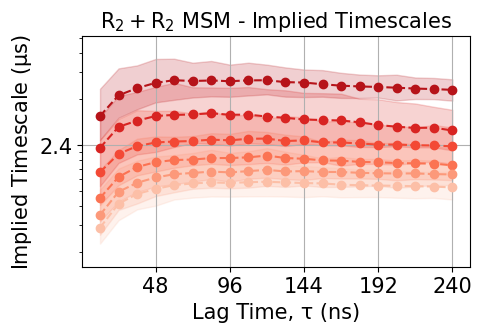

In [15]:
from writhe_tools.utils import symbols
import matplotlib.ticker as ticker
from deeptime.plots import plot_implied_timescales
from deeptime.util.validation import implied_timescales
from writhe_tools.plots import annotated_matrix_plot
from writhe_tools.utils import contiguous_bool
from writhe_tools.utils import indices_stat
from writhe_tools.stats import mean
from writhe_tools.md_tools import rmsd_sort
from writhe_tools.md_tools import canonical_residues
from writhe_tools.utils import split_list

its = implied_timescales(bayes)
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
ax.set_yscale("log")
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x * 0.24e-3:.1f}"))
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x * 0.24:.0f}"))
plot_implied_timescales(its,
                        ax=ax,
                        colors = get_color_list(6, 'Reds_r', 60, 45),
                        n_its=6,
                        show_mle=False)
#ax.set_xticks(np.arange(len(lags)), np.round(lags * .24, 1))
#ax.set_xlim(5, 15)
ax.set_ylabel(r"Implied Timescale ($\mu$s)", size=15)
ax.set_xlabel(f"Lag Time, {symbols('tau')} (ns)", size=15)
plt.title(r"$R_{2} + R_{2}$ MSM - Implied Timescales",size = 15)
ax.tick_params('both', labelsize = 15)
ax.tick_params('x', labelsize = 15)
#ax.set_xlim(0, 420)
ax.set_ylim(1600,)
ax.grid()

In [10]:
msm_index = -10

In [278]:
np.where(lags == lags[::2][msm_index])

(array([0]),)

<Axes: title={'center': 'MFPT Matrix : APO'}, xlabel='$State_{i}$', ylabel='$State_{j}$'>

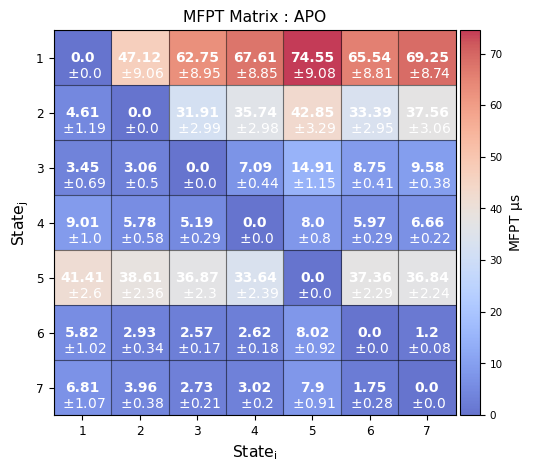

In [14]:

mfpt_mean, mfpt_error = bayes_mfpt_matrix(bayes[msm_index], sets)

annotated_matrix_plot(mfpt_mean * 0.24e-3,
                      mfpt_error * 0.24e-3,
                      decimals=2,
                      cmap='coolwarm', 
                      alpha=.78,
                      title = f'MFPT Matrix : {label}',
                      font_scale=.25,
                      cbar_label=r'MFPT $\mu$s',
                      grid=True, 
                      grid_alpha=.3, 
                      figsize=(5.5,5)
                      )

In [280]:


flux = np.stack([flux_matrix(i, sets) for i in bayes[msm_index].samples])
flux /= flux.sum(2, keepdims=True)
flux_mu = flux.mean(0)
flux_err = np.diff(np.percentile(flux, [2.5, 97.5], axis=0), axis=0).squeeze() / 2 

<Axes: title={'center': 'R2 + R2 APO MSM Macrostate Flux Matrix'}, xlabel='$State_{i}$', ylabel='$State_{j}$'>

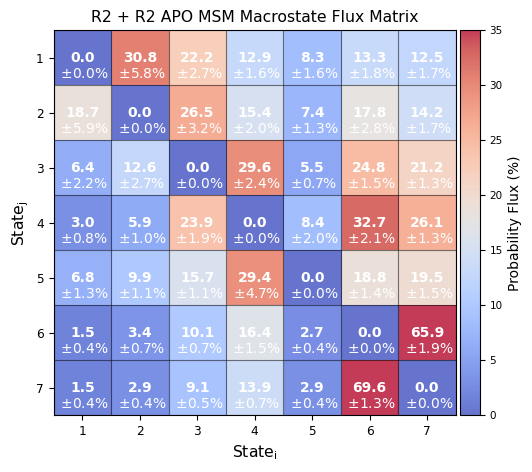

In [281]:
annotated_matrix_plot(flux_mu * 100,
                      flux_err * 100,
                      decimals=1,
                      cmap='coolwarm', 
                      alpha=.78,
                      font_scale=.25,
                      title = r"R2 + R2 APO MSM Macrostate Flux Matrix",
                      unit = "%",
                      cbar_label = r"Probability Flux (%)",
                      grid=True, 
                      grid_alpha=.3, 
                      figsize=(5.5,5), vmax=35,
                      )

In [283]:
for i in range(7):
    print(np.fromiter(map(len, contiguous_bool(bools=macrostates == i)), int).mean())

25.46650124069479
9.497333333333334
14.443516699410608
19.860711582134748
74.72079772079772
13.897986182566514
29.197067238912734


In [21]:

def bayes_pi(bmsm, sets, ci: float = 0.95):
    
    stats = bmsm.gather_stats('stationary_distribution', confidence=ci)
    err = (abs(stats.mean - stats.L) + abs(stats.mean - stats.R)) / 2
    
    return indices_stat(sets, stats.mean, np.sum)[0], indices_stat(sets, err, np.linalg.norm)[0]

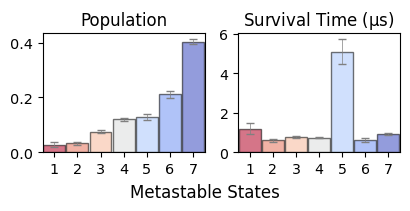

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(4.2, 2.3))

stationary_mu, stationary_err = bayes_pi(bayes[msm_index], sets)
box_plot(stationary_mu,
         stationary_err,
         cmap='coolwarm_r',
         alpha=.55,
         ax=axes[0],
         font_scale=1.73,
         error_capsize=3,
         title='Population')
axes[0].set_title('Population')


survival_times = []
ids = set(range(len(sets)))
for i in range(len(sets)):
    survival_times.append(bayes_mfpt(bayes[msm_index], sets[i], list(chain(*reindex_list(sets, list(ids - {i}))))))
survival_times = np.array(survival_times)

box_plot(survival_times.T[0] * 0.24e-3, 
         errors = survival_times.T[1] * 0.24e-3,
         cmap='coolwarm_r', 
         alpha=.55,
         ax=axes[1],
         font_scale=1.7,
         error_capsize=3,
         title='Population')

axes[1].set_title(r'Survival Time ($\mu$s)')
fig.supxlabel('Metastable States',
              y=0.1,
             )
fig.tight_layout()


In [23]:
np.stack([stationary_mu, stationary_err], 1)

array([[0.02826781, 0.00896864],
       [0.03252742, 0.00549661],
       [0.07510864, 0.00589057],
       [0.11989647, 0.00671784],
       [0.12967417, 0.01033249],
       [0.21074172, 0.01196258],
       [0.40378377, 0.00927979]])

In [ ]:
writhe.compute_writhe(1, cuda=True)

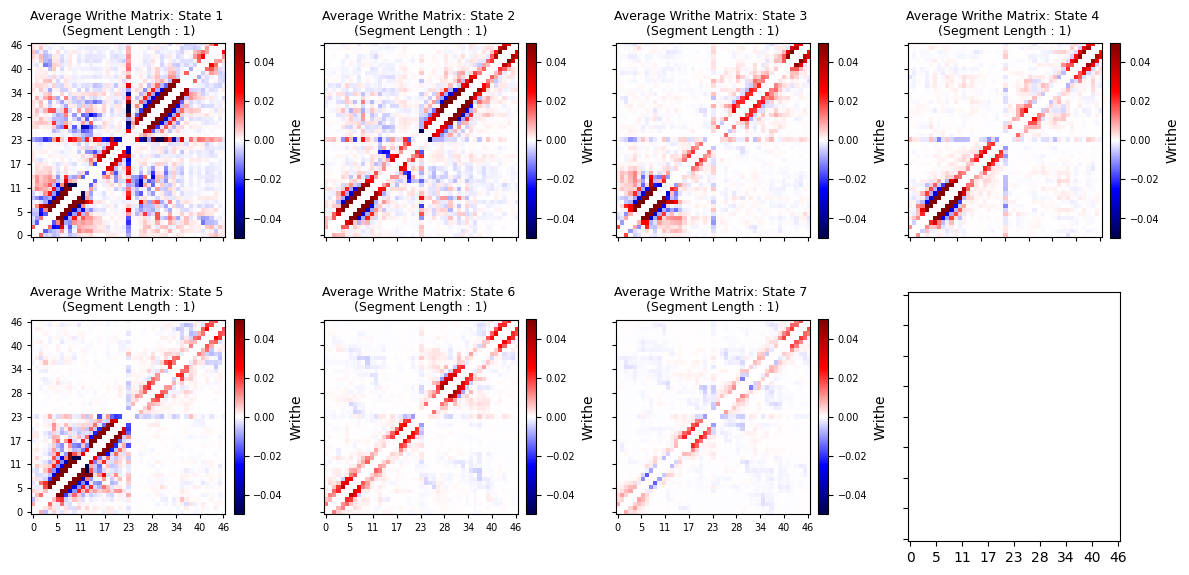

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6), sharex=True, sharey=True)
for i, (ax, frames) in enumerate(zip(axes.flat, group_by(macrostates))):
    writhe.plot_writhe_matrix(frames, ax=ax, dscr=f'State {i+1}', vmax=0.05)
fig.tight_layout()
    
    

In [ ]:
samples = []
for i in range(7):weighted_mean = lambda x : mean(x[:, :-1], weights = x[:, -1].reshape(-1, 1))
    sample = bayes[msm_index].evaluate_samples('mfpt',
                                      A=sets[i],
                                      B=list(chain(*reindex_list(sets, list(ids - {i})))))
    samples.append(sample)
for i, sample in enumerate(samples):
    plt.hist(sample, bins=25, histtype='step', label=i+1)
plt.legend()

In [53]:
weights = (bayes[msm_index].gather_stats('stationary_distribution', confidence=0.95).mean
           / group_by(msm.dtraj, reduction=np.sum))[msm.dtraj]

In [54]:

weighted_mean = lambda x : mean(x[:, :-1], weights = x[:, -1].reshape(-1, 1))
group_by(macrostates, np.stack([ca_distances.contacts(1).any(1), weights], 1), weighted_mean)
group_by(macrostates, ca_distances.contacts(1).any(1), np.mean)

In [144]:
#features = np.concatenate([dssp.transpose(1, 0, 2).reshape(-1, 48), ca_distances.contacts(1)], 1)
#features = writhe_features
features = proj[:, :2]
mus = group_by(macrostates, np.concatenate([features,  weights[:, None]], 1), weighted_mean)
writhe_centroids = []
for frames, center in zip(group_by(macrostates), mus):
    writhe_centroids.append(frames[np.linalg.norm(features[frames] - center, axis=-1).argsort()])

In [136]:
traj = md.load('./apo_pbc_correct.dcd', top=protein_pdb)


(0.7, 2.0)

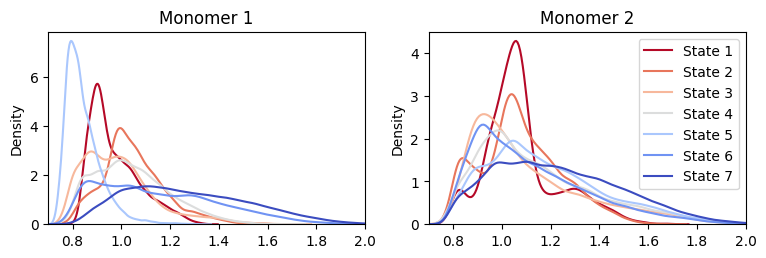

In [133]:
from seaborn import kdeplot

sequence, ca_indices = get_residues(traj)
selection = ' or '.join([f'residue {j}' for j, i in enumerate(sequence) if num_str(i, reverse=True) in canonical_residues])
rgs = [md.compute_rg(traj_slice(traj, ' or '.join(s))) for s in split_list(selection.split(' or '), 2)]

colors = get_color_list(7, 'coolwarm_r')

fig, axes = plt.subplots(1, 2, figsize=(9, 2.5), sharex=True, sharey=False)
for i, (frames, c) in enumerate(zip(group_by(macrostates), colors)):
    kdeplot(rgs[0][frames], ax=axes[0], color=c, label=f'State {i+1}')
    kdeplot(rgs[1][frames], ax=axes[1], color=c, label=f'State {i+1}')
axes[1].legend()
axes[0].set_title('Monomer 1')
axes[1].set_title('Monomer 2')
axes[0].set_xlim(0.5, 2)
axes[1].set_xlim(0.7, 2)

In [97]:
import visualize
reload(visualize)
del visualize
from visualize import visualize_clustering


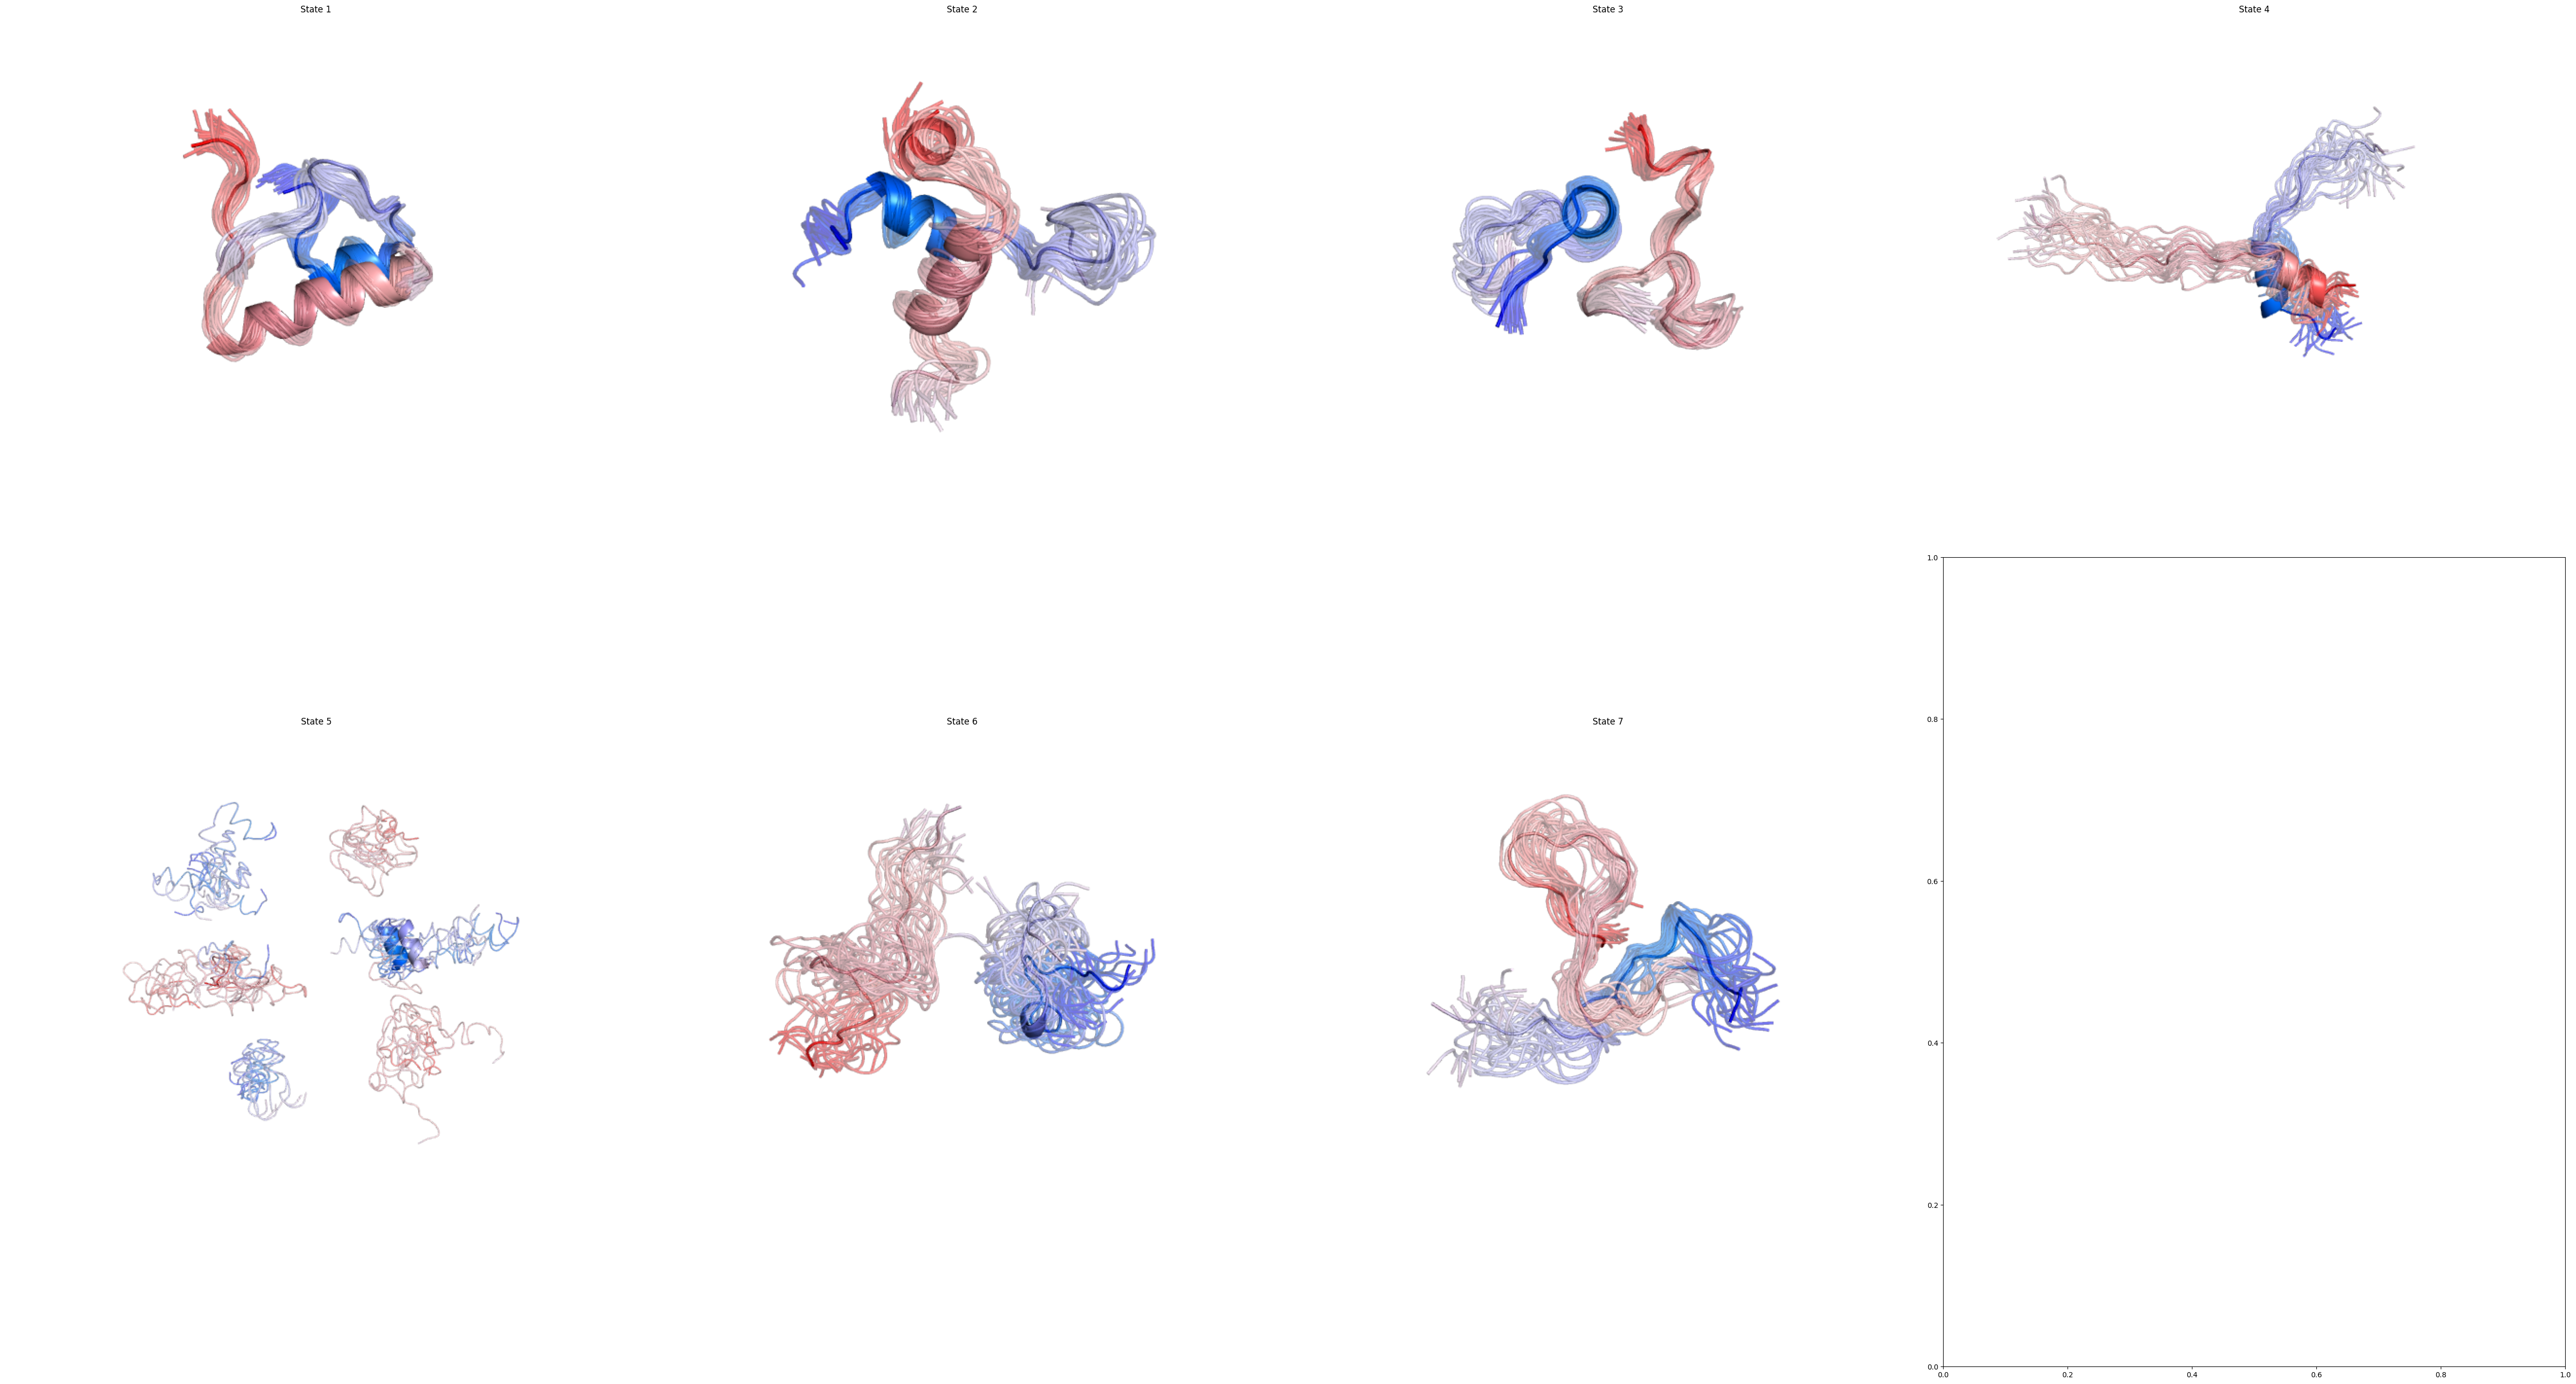

In [156]:
from visualize import visualize_clustering
fig, axes = plt.subplots(2, 4, figsize=(50, 30))
for i, (frames, ax) in enumerate(zip(writhe_centroids, axes.flat)):
    indices = rmsd_sort(frames, traj, 6)
    visualize_clustering(traj,
                         indices,
                         path='./',
                         name = f"State {i+1}",
                         n_frames=25, 
                         draw_style='cartoon',
                         ensemble_draw_style='loop',
                         transparency=.45,
                         ax=ax)
fig.tight_layout()

In [163]:
import numpy as np
import matplotlib.pyplot as plt

from matplotlib import gridspec
from matplotlib.patches import Rectangle
from mpl_toolkits.axes_grid1 import make_axes_locatable, axes_size


def build_matrix_boxplot_grid(matrix: np.ndarray,
                              bottom_values: np.ndarray,
                              left_values: np.ndarray,
                              title: str = None,
                              title_size: int = 20,
                              left_title: str = None,
                              bottom_title: str = None,
                              marginal_max: int = None,
                              cmap: str = "jet",
                              figsize: tuple = (6, 6),
                              wspace: float = 0.05,
                              hspace: float = 0.05,
                              width_ratios: tuple = (1, 4, 0.15),
                              height_ratios: tuple = (1, 4, 1),
                              vmin: float = 0,
                              vmax: float = 1,
                              cbar_label: str = None,
                              ticks: list = None,
                              n_yticks: int = 3,
                              left_errors: np.ndarray = None,
                              bottom_errors: np.ndarray = None,
                              ecolor: str = 'gray',
                              outline: bool = True,
                              outline_color: str = "gray",
                              outline_lw: float = .8,
                              outline_alpha: float = 0.3,
                              font_scale: float = 1.0,
                              matrix_aspect="equal",
                              sharex: bool = True,
                              sharey: bool = True,
                              ytick_label_width: float = 0.18,
                              subplot_pad: float = 0.02,
                              bottom_pad: float = 0.2,
                              path: str = None,
                              ax=None):

    """
    Heat-map with marginal bar plots.

    * Matrix panel: rectangle outlines around every pixel.
    * Left / bottom bar panels: centred ticks only.
    * Optional: error bars and box border highlighting.
    """

    subplot_mode = ax is not None
    nrows, ncols = matrix.shape

    if ax is None:
        fig = plt.figure(figsize=figsize, constrained_layout=True)
        spec = gridspec.GridSpec(ncols=3, nrows=3, figure=fig,
                                 width_ratios=width_ratios,
                                 height_ratios=height_ratios,
                                 wspace=wspace, hspace=hspace)

        ax_matrix = fig.add_subplot(spec[1, 1])
        ax_left = fig.add_subplot(spec[1, 0], sharey=ax_matrix if sharey else None)
        ax_bottom = fig.add_subplot(spec[2, 1], sharex=ax_matrix if sharex else None)
        cax = fig.add_subplot(spec[1, 2])
        ax_label = None

    else:
        fig = ax.figure
        ax_matrix = ax

        divider = make_axes_locatable(ax_matrix)

        left_size = f"{100 * width_ratios[0] / width_ratios[1]}%"
        bottom_size = f"{100 * height_ratios[2] / height_ratios[1]}%"
        cbar_size = f"{100 * width_ratios[2] / width_ratios[1]}%"

        if ticks is not None:
            ax_label = divider.append_axes(
                "left",
                size=axes_size.Fixed(ytick_label_width),
                pad=0.01,
                sharey=ax_matrix if sharey else None
            )

            ax_left = divider.append_axes(
                "left",
                size=left_size,
                pad=subplot_pad,
                sharey=ax_matrix if sharey else None
            )
        else:
            ax_label = None
            ax_left = divider.append_axes(
                "left",
                size=left_size,
                pad=subplot_pad,
                sharey=ax_matrix if sharey else None
            )

        ax_bottom = divider.append_axes(
            "bottom",
            size=bottom_size,
            pad=bottom_pad,
            sharex=ax_matrix if sharex else None
        )

        cax = divider.append_axes(
            "right",
            size=cbar_size,
            pad=subplot_pad
        )

    # ---------------------------------------------------------------- Matrix
    im = ax_matrix.imshow(matrix, aspect=matrix_aspect, cmap=cmap,
                          vmin=vmin, vmax=vmax, alpha=.85)

    ax_matrix.tick_params(left=False, bottom=False,
                          labelleft=False, labelbottom=False)

    ax_matrix.set_xlim(-0.5, ncols - 0.5)
    ax_matrix.set_ylim(nrows - 0.5, -0.5)

    if title:
        ax_matrix.set_title(title, size=title_size * font_scale)

    if outline:
        for i in range(nrows):
            for j in range(ncols):
                ax_matrix.add_patch(Rectangle(
                    (j - 0.5, i - 0.5), 1, 1,
                    edgecolor=outline_color,
                    facecolor="none",
                    lw=outline_lw,
                    alpha=outline_alpha
                ))

    # ---------------------------------------------------------- Left bar plot
    bar_kwargs = dict(
        color="indianred",
        alpha=.85,
        edgecolor="black",
        linewidth=0.5
    )

    ax_left.barh(np.arange(nrows), left_values, **bar_kwargs)

    if left_errors is not None:
        ax_left.errorbar(left_values, np.arange(nrows), xerr=left_errors,
                         fmt='none', ecolor=ecolor, capsize=2, lw=0.8)

    left_max = max(vmax, bottom_values.max(), left_values.max()) if marginal_max is None else marginal_max
    ax_left.set_xlim(vmin, left_max)
    ax_left.set_ylim(nrows - 0.5, -0.5)
    ax_left.invert_xaxis()
    ax_left.xaxis.tick_top()
    ax_left.minorticks_off()

    xticks = np.linspace(vmin, left_max, 3)[:-1] if n_yticks == 2 else np.linspace(vmin, left_max, n_yticks)
    ax_left.set_xticks(xticks)
    ax_left.set_xticklabels(
        [f"{x:.0f}" if x.is_integer() else f"{x:.1f}" for x in xticks],
        fontsize=14 * font_scale
    )

    if subplot_mode and ticks is not None:
        ax_left.set_yticks([])
    else:
        ax_left.yaxis.tick_right()

    if left_title:
        ax_left.set_ylabel(left_title, rotation=90, labelpad=8, size=18 * font_scale)
        ax_left.yaxis.set_label_position("left")

    # -------------------------------------------------------- Bottom bar plot
    bar_kwargs = dict(
        color="skyblue",
        alpha=.6,
        edgecolor="black",
        linewidth=0.5
    )

    ax_bottom.bar(np.arange(ncols), bottom_values, **bar_kwargs)

    if bottom_errors is not None:
        ax_bottom.errorbar(np.arange(ncols), bottom_values, yerr=bottom_errors,
                           fmt='none', ecolor=ecolor, capsize=2, lw=0.8)

    bottom_max = max(vmax, bottom_values.max(), left_values.max()) if marginal_max is None else marginal_max
    ax_bottom.set_xlim(-0.5, ncols - 0.5)
    ax_bottom.set_ylim(vmin, bottom_max)
    ax_bottom.minorticks_off()
    ax_bottom.yaxis.tick_right()

    yticks = np.linspace(vmin, bottom_max, 3)[:-1] if n_yticks == 2 else np.linspace(vmin, bottom_max, n_yticks)
    ax_bottom.set_yticks(yticks)
    ax_bottom.set_yticklabels(
        [f"{y:.0f}" if y.is_integer() else f"{y:.1f}" for y in yticks],
        fontsize=14 * font_scale
    )

    if bottom_title:
        ax_bottom.set_xlabel(bottom_title, labelpad=8, size=18 * font_scale)
        ax_bottom.xaxis.set_label_position("bottom")

    # -------------------------------------------------------------- Colorbar
    cbar = fig.colorbar(im, cax=cax)
    cbar.ax.tick_params(labelsize=14 * font_scale)

    if cbar_label:
        cbar_labelpad = 16 if subplot_mode else 16
        cbar.set_label(cbar_label, rotation=-90,
                       labelpad=cbar_labelpad,
                       size=20 * font_scale)

    cbar_ticks = np.linspace(im.norm.vmin, im.norm.vmax, 5)
    if subplot_mode:
        cbar_ticks = cbar_ticks[1:]

    cbar.set_ticks(cbar_ticks)
    cbar.set_ticklabels([f"{t:.0f}" if t.is_integer() else f"{t:.1f}" for t in cbar_ticks])

    # ---------------------------------------- Centre ticks on bar plots only
    pos_x = np.arange(ncols)

    ax_bottom.set_xticks(pos_x)

    if ticks is not None:
        ax_bottom.set_xticklabels(ticks, rotation=0, fontsize=12 * font_scale)

        if subplot_mode:
            ax_label.set_xlim(0, 1)
            ax_label.set_ylim(nrows - 0.5, -0.5)
            ax_label.set_xticks([])
            ax_label.set_yticks([])

            for i, tick in enumerate(ticks):
                ax_label.text(0.5, i, tick,
                              ha='center',
                              va='center',
                              fontsize=11 * font_scale)

            for spine in ax_label.spines.values():
                spine.set_visible(False)
        else:
            pos_y = np.arange(nrows)
            ax_left.set_yticks(pos_y)
            ax_left.set_yticklabels(ticks,
                                    ha='left',
                                    va='center',
                                    fontsize=11 * font_scale)
    else:
        ax_bottom.set_xticklabels([])
        ax_left.set_yticklabels([])

    if path is not None:
        fig.savefig(path, dpi=1000, bbox_inches='tight')

    if ax is None:
        plt.show()

    return fig, (ax_matrix, ax_left, ax_bottom, cax)

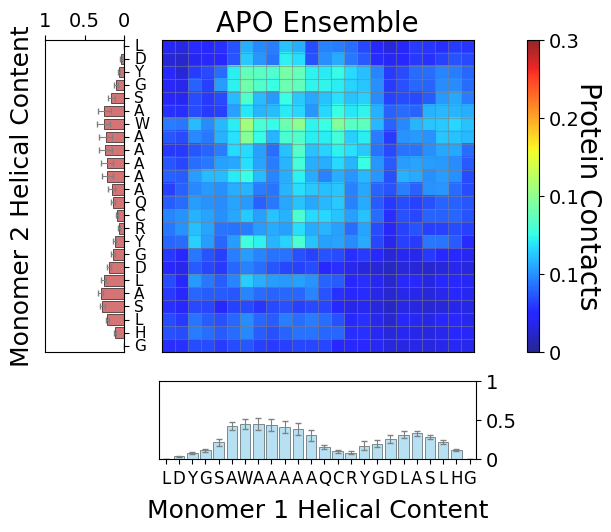

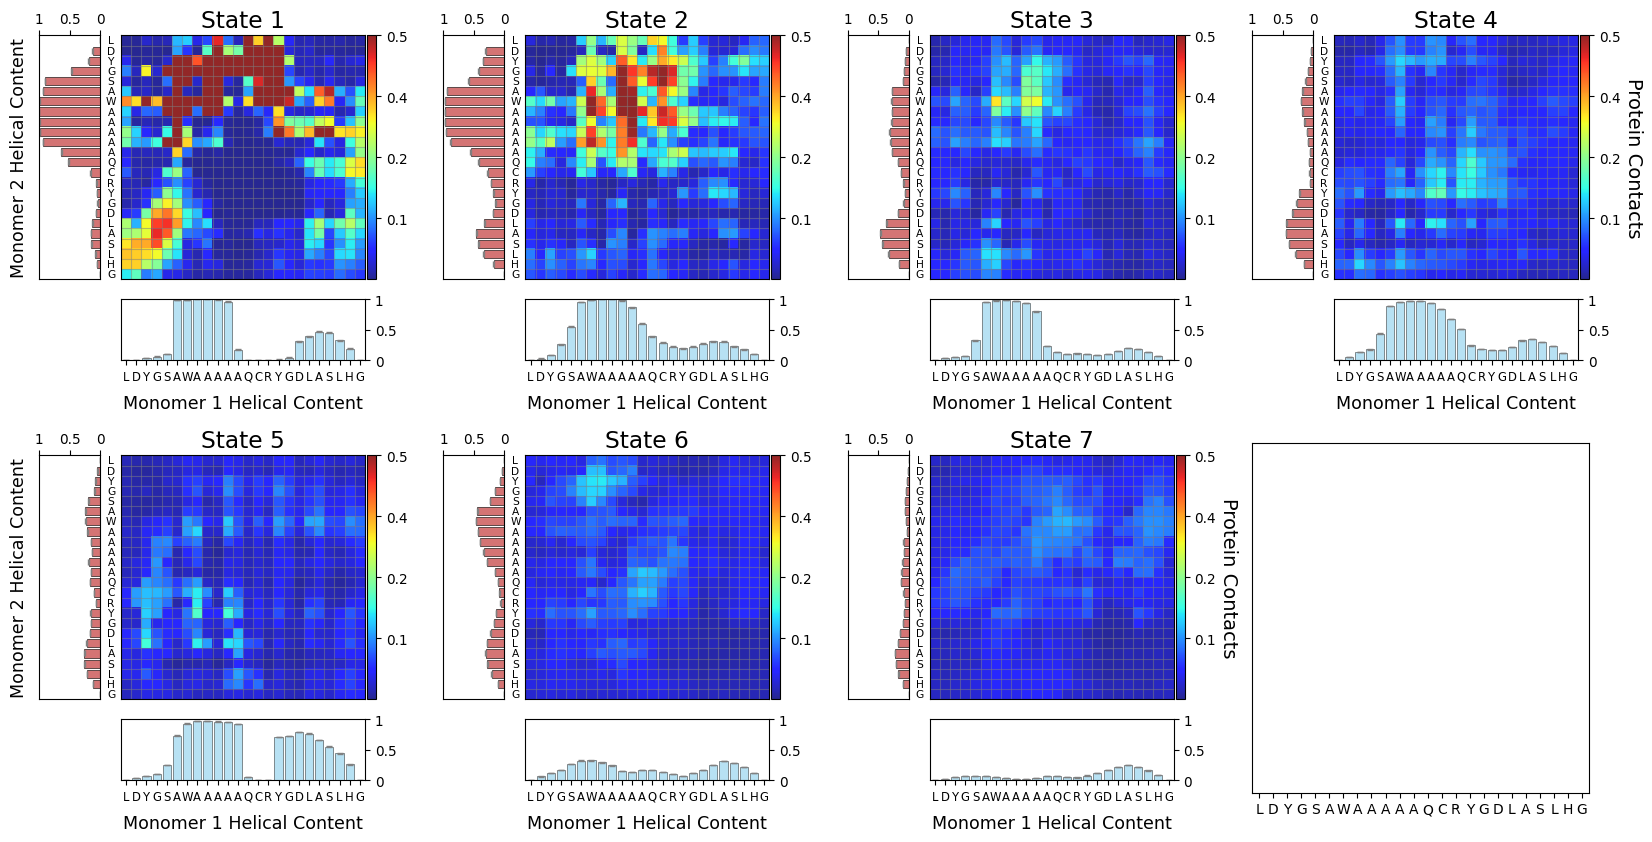

In [165]:
import writhe_tools
reload(writhe_tools)
reload(writhe_tools.plots)
#from writhe_tools.plots import build_matrix_boxplot_grid
dssp_error = split(block_error(dssp.transpose(1, 0, 2).reshape(-1, 48))[1])

build_matrix_boxplot_grid(ca_distances.matrix(contacts=True, cut_off=1).mean(0).T,
                          dssp[0].mean(0),
                          dssp[1].mean(0),
                          bottom_errors=dssp_error[0],
                          left_errors=dssp_error[1],
                          cmap='jet',
                          title=f'{label} Ensemble',
                          bottom_title='Monomer 1 Helical Content',
                          vmin=0,
                          vmax=.3,
                          marginal_max=1,
                          left_title='Monomer 2 Helical Content',
                          cbar_label='Protein Contacts',
                          ticks=codes,
                          ecolor='gray',
                          path=f'{paths[0]}/protein_protein_helix_ensemble.png'
                         )

fig, axes = plt.subplots(2, 4, figsize=(20, 10), sharey=True, sharex=True)
for i, (ax, frames) in enumerate(zip(axes.flat, group_by(macrostates))):
    dssp_error = split(bootstrap(dssp.transpose(1, 0, 2).reshape(-1, 48)[frames], 0.95)[1])

    build_matrix_boxplot_grid(ca_distances.matrix(contacts=True, cut_off=1, index=frames).mean(0).T,
                          dssp[0][frames].mean(0),
                          dssp[1][frames].mean(0),
                          title_size=24,
                          bottom_errors=dssp_error[0],
                          left_errors=dssp_error[1],
                          cmap='jet',
                          title=f'State {i+1}', #f'{label} : State {i+1}',
                          bottom_title='Monomer 1 Helical Content',
                          vmin=0,
                          vmax=.5,
                          marginal_max=1,
                          left_title='Monomer 2 Helical Content' if (i == 0 or i == 4) else '',
                          cbar_label='Protein Contacts' if (i == 3 or i == 6) else '' ,
                          ticks=codes,
                          ax=ax,
                          font_scale=.7,
                          #path=f'{paths[0]}/protein_protein_helix_state_{i+1}.png',
                             )
#fig.tight_layout()


In [103]:
def brownian_simulation():
    x = 0
    ts = np.linspace(0, 1, 1000)
    dt = ts[1] - ts[0]
    traj = []
    for i in ts:
        x += np.sqrt(dt) * np.random.normal()
        traj.append(x)
    return traj

trajs = np.stack([brownian_simulation() for i in range(10000)])
for i in trajs:
    plt.plot(np.linspace(0, 1, 1000), i)
normal = lambda x, mu=0, sigma=1 : ( 1 / np.sqrt(2 * np.pi * sigma ** 2)) * np.exp(- (x - mu) ** 2 / (2 * sigma ** 2))
x = np.linspace(-3.5, 3.5, 1000)

plt.plot(x, normal(x))
_=plt.hist(trajs[:, -1], histtype='step', density=True, bins=100)
        

In [605]:
from deeptime.decomposition.deep import vampnet_loss

In [624]:
import sys
sys.path.append('/home/t/Downloads/final_scripts/scripts')
from final import KoopmanModel, TimeSeriesData, DataSet

In [631]:
import torch
import torch.nn as nn
from torch.optim import Adam
from writhe_tools.stats import pca

In [943]:
data = pca(writhe_features, scale=False, scale_projection=True, n_comp=500)[0]

In [738]:
#data = data[:, :250]

In [948]:
writhe_features.shape

(416660, 991)

In [947]:
nn.TransformerEncoder(

torch.nn.modules.transformer.TransformerEncoder

In [952]:
from writhe_tools.stats import center, standardize

In [ ]:
data_generator = TimeSeriesData(standardize(writhe_features), 0.99)
net = nn.Sequential(nn.LazyLinear(500), nn.GELU(),
                    nn.Linear(500, 500), nn.GELU(),
                    nn.Linear(500, 10), nn.Softmax(1)
                   )
optim = Adam(net.parameters(), lr = 1e-3)

net.train()
train_dataset, val_dataset = [DataSet(i) for i in data_generator(100)]

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32768 // 4,
                                                   pin_memory=False, num_workers=0,
                                                   shuffle=True, drop_last=False)

val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=4096,
                                         pin_memory=False, num_workers=0,
                                         shuffle=True, drop_last=False)



for _ in range(1):
    for batch in train_loader:
        x0, xt = net(batch[..., 0]), net(batch[..., 1])
        loss = vampnet_loss(x0, xt, method='VAMP1')
        loss.backward()
        optim.step()
    print(loss.item())

print('Finished VAMP1 score training, moving to VAMP2 score training ... ')

for _ in range(2):
    for batch in train_loader:
        x0, xt = net(batch[..., 0]), net(batch[..., 1])
        loss = vampnet_loss(x0, xt, method='VAMP2')
        loss.backward()
        optim.step()
    print(loss.item())   

chi = net(torch.Tensor(data)).detach().numpy()
tcca = tCCA(chi, 100, epsilon=1e-6).fit_transform()
fes2d(tcca[:, :2], bins=25, n_contours=18, mask=False, extend_border=.5)       

In [ ]:
np.save('indices.npy', data_generators.indices,)


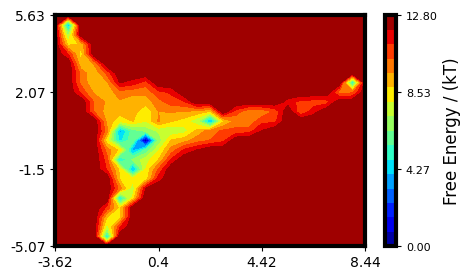

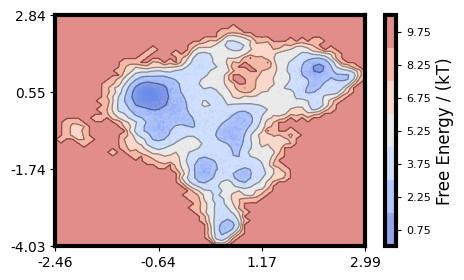

In [603]:
lag = 500
counts = np.stack([pmf([macrostates[:-lag * i], macrostates[i * lag:]], 7, norm=False)[0] for i in range(1, 10)])
ps = counts / counts.sum(-1, keepdims=True)

changing pred
changing est


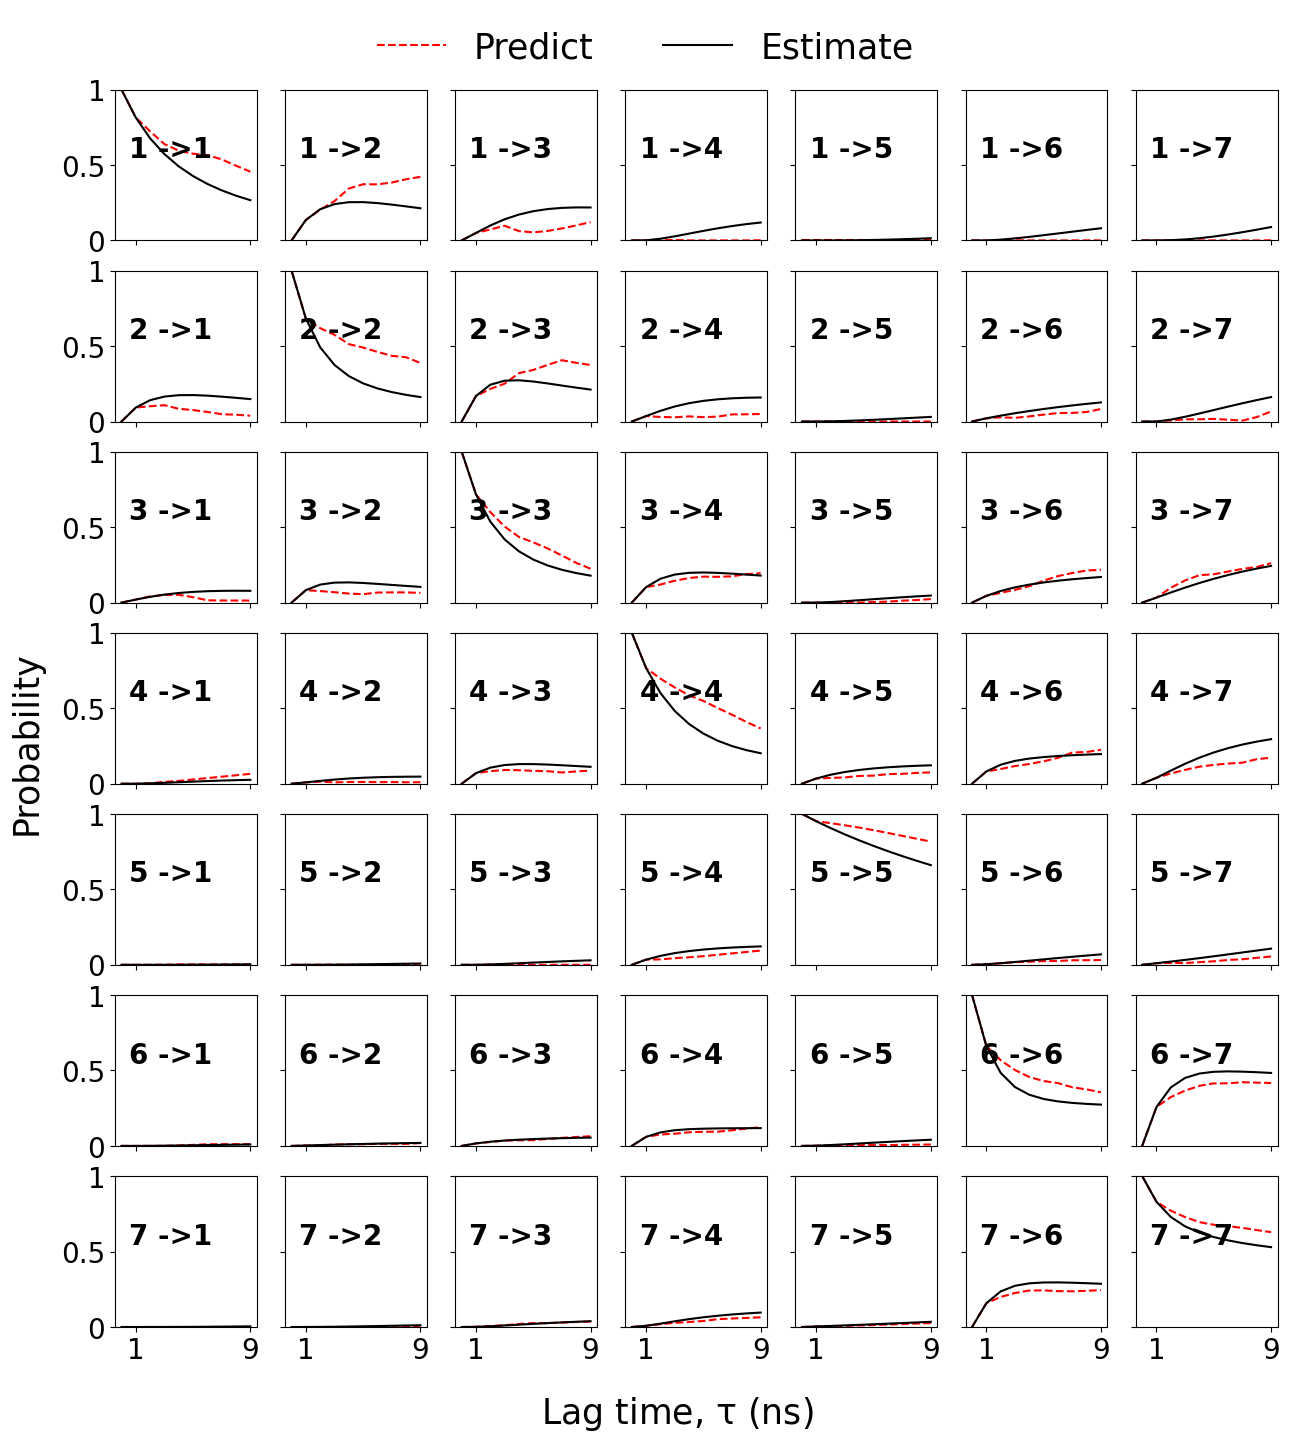

In [604]:
from writhe_tools.msm_tools import plot_cktest
plot_cktest(counts / counts.sum(-1, keepdims=True), np.stack([np.linalg.matrix_power(ps[0], i) for i in range(1, 10)]))

<Axes: title={'center': 'Transition Matrix'}, xlabel='$State_{i}$', ylabel='$State_{j}$'>

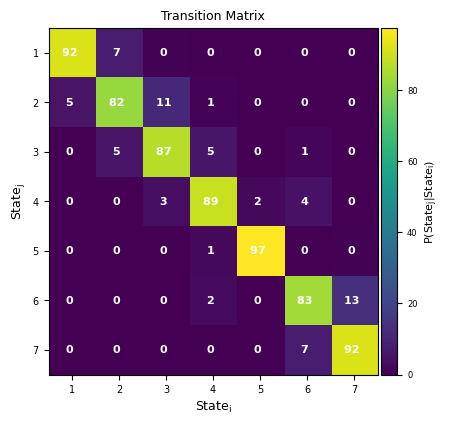

In [561]:
annotated_matrix_plot(100 * counts / counts.sum(-1, keepdims=True), figsize=(4.5, 4.5), font_scale=.2,round_int=True)

<Axes: title={'center': 'Transition Matrix'}, xlabel='$State_{i}$', ylabel='$State_{j}$'>

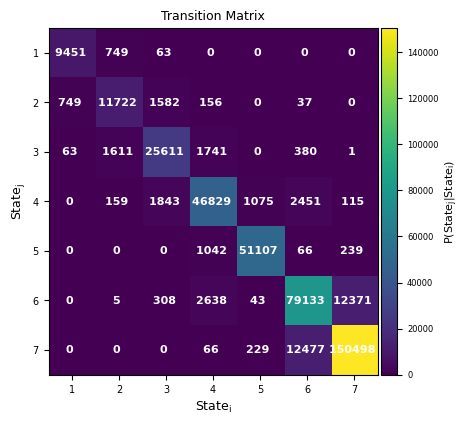

In [558]:
annotated_matrix_plot(counts, figsize=(4.5, 4.5), font_scale=.2,round_int=True)

In [443]:
def acf(x):
    """
    Computes the autocorrelation function (ACF) of a 1D time series using FFT.

    Parameters:
    - x (np.ndarray): Input 1D signal.

    Returns:
    - acf (np.ndarray): The autocorrelation function.
    """
    N = len(x)
    x = x - np.mean(x)
    return np.fft.ifft(np.abs(np.fft.fft(x, n=2*N))**2).real[:N] / (N * np.var(x))

def get_time(acf, cutoff=np.exp(-1)):

    return np.sum(acf[:(acf <= cutoff).argmax() + 1])
    
import ray
@ray.remote
def get_acf_time(x, cutoff=np.exp(-1)):
    return get_time(acf(x), cutoff=np.exp(-1))

inter_writhe_correlations = np.array(ray.get([get_acf_time.remote(i) for i in ])).reshape(23, 23)

2026-04-23 16:52:37,123	INFO worker.py:2004 -- Started a local Ray instance. View the dashboard at 127.0.0.1:8265 


In [471]:
writhe_features[:, -23 ** 2:]

array([[-5.7815650e-04,  6.6908699e-04, -9.5015515e-05, ...,
         1.1711793e-03, -8.4409752e-05, -9.6605672e-04],
       [-1.6776557e-03, -3.5971380e-04, -2.0399498e-04, ...,
         3.5103850e-04, -2.3182800e-04, -4.9870339e-04],
       [-8.0913072e-04, -8.0310693e-04, -1.0237884e-03, ...,
        -2.3740598e-04, -3.1393257e-04, -1.3069339e-02],
       ...,
       [ 1.4878333e-03,  1.5223732e-04, -1.7888076e-03, ...,
        -6.6105794e-04, -5.4939382e-04, -2.2558596e-04],
       [ 1.3623001e-03,  1.8688155e-05, -1.0762203e-03, ...,
         2.2913386e-04,  2.6660716e-02,  1.8779225e-04],
       [-3.5086520e-02, -5.0745456e-04,  3.0900307e-02, ...,
        -8.0046018e-05,  1.9895419e-02, -1.7881814e-04]], dtype=float32)

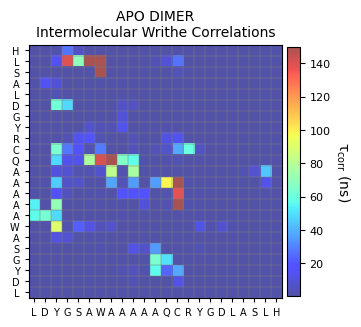

In [480]:
plot_distance_matrix(inter_writhe_correlations * 0.24,
                     grid=True,
                     grid_alpha=.65,
                     alpha=.68,
                     vmax=150,
                     cbar_label=r'$\tau_{corr}$ (ns)',
                     xticks=codes[:-1], 
                     yticks=codes[:-1],
                     title= 'APO DIMER\nIntermolecular Writhe Correlations',
                     figsize=(3.5, 3.5)
                    
                    )

In [233]:
survival_times

[600.9684745194562,
 362.02194691875445,
 104.68776874110175,
 59.86726430833805,
 342.35095574986184,
 28.114187069262318,
 34.61586802032381]

In [265]:
mode =lambda x : np.bincount(x).argmax()
sets = group_by(*group_by(msm.dtraj, macrostates, mode, return_keys=True))
micro_centroids = group_by(msm.dtraj, proj, lambda x : x.mean(0))
bound_states = group_by(msm.dtraj, ca_distances.contacts(1).any(1), np.mean)
sa_states = group_by(msm.dtraj, sa.sum((0, 2)), 
                     np.mean)

In [272]:
vec = np.abs(msm.msm['msms'][4].eigenvectors_left())
vec_idx = 3
end_states = np.array([vec.T[vec_idx].argmin(), vec.T[vec_idx].argmax()])

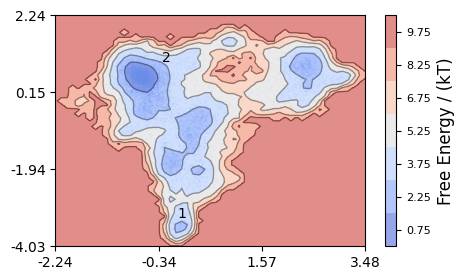

In [273]:
fes2d(proj[:, :2], cluster_centers=micro_centroids[end_states], **fes2d_args)

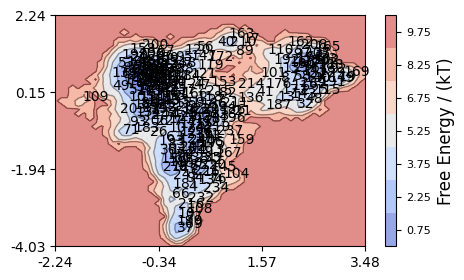

In [274]:
fes2d(proj[:, :2], cluster_centers=micro_centroids, **fes2d_args)

In [290]:
end_states

array([ 9, 49])

In [399]:
path = np.concatenate(reindex_list(msm.msm['msms'][0].reactive_flux( [9,], [49]).pathways()[0], [0])
                      #+reindex_list(msm.msm['msms'][0].reactive_flux( [13,], [40]).pathways()[0], [0, 1, 3, 4, 5])
                      #reindex_list(msm.msm['msms'][0].reactive_flux( [7,], [4]).pathways()[0], [0, 1, 3, 4, 5])
                     )
path = np.unique(path)

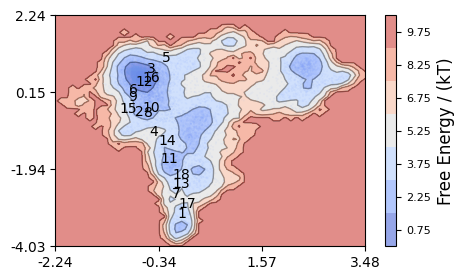

In [400]:
fes2d(proj[:, :2], cluster_centers=micro_centroids[path], **fes2d_args)

TypeError: can't multiply sequence by non-int of type 'float'

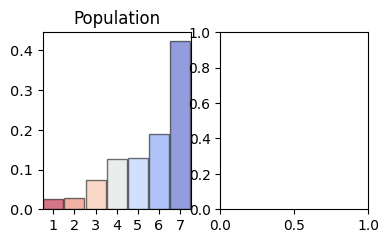

In [310]:
stationary_distribution * 100

array([ 2.54616534,  3.29390988,  7.07242295, 12.64287586, 12.67714374,
       20.88379257, 40.88368966])

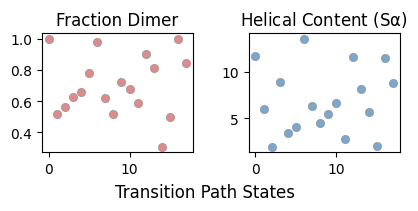

In [403]:
fig, axes = plt.subplots(1, 2, figsize=(4.2, 2.3))
s=None
axes[0].scatter(np.arange(len(path)),
                bound_states[path], alpha=.7,
                edgecolors='gray',
                color='indianred' ,s=s, linewidths=.5)
axes[0].set_title('Fraction Dimer')
axes[1].scatter(np.arange(len(path)), sa_states[path], alpha=.7, edgecolors='gray', color='steelblue', s=s, linewidths=.5)
axes[1].set_title(r'Helical Content (S$\alpha$)')
#fig.supxlabel('Transition Pathway State', y=-0.15)
fig.supxlabel('Transition Path States',
              y=0.1,
             )
#fig.suptitle(r'Slowest Process (~1.92$\mu$s)', y=1.2)
fig.tight_layout()

## survival_times = np.array(survival_times)

NameError: name 'stationary_distribution' is not defined

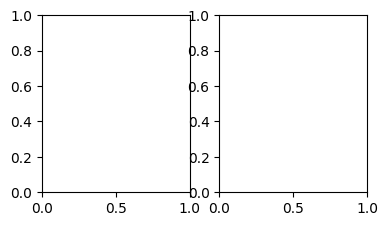

In [234]:
fig, axes = plt.subplots(1, 2, figsize=(4.2, 2.3))
box_plot(stationary_distribution, cmap='coolwarm_r', alpha=.55, ax=axes[0], font_scale=1.73, title='Population')
axes[0].set_title('Population')

box_plot(survival_times * 500 * 0.24e-3, 
         cmap='coolwarm_r', 
         alpha=.55,
         ax=axes[1],
         font_scale=1.7,
         title='Population')

axes[1].set_title(r'Survival Time ($\mu$s)')
fig.supxlabel('Metastable States',
              y=0.1,
             )
fig.tight_layout()

# box_plot(group_by(macrostates,(ca_distances.contacts(1).sum(-1) > 30), np.mean), 
#          cmap='coolwarm_r', 
#          alpha=.55,
#          ax=axes[1],
#          font_scale=1.7,
#          title='Population')

# axes[1].set_title('Fraction Dimer')
# fig.supxlabel('Metastable States',
#               y=0.1,
#              )
# fig.tight_layout()

 # Visualize latent space